# Speech Emotion Recognition on RAVDESS Using LSTM and Transformer Networks
ARTI 502 – Final Project

## 1. Setup

In [ ]:
!pip install -q librosa soundfile scikit-learn seaborn pandas matplotlib scipy

In [ ]:
%pip install librosa soundfile scikit-learn seaborn pandas matplotlib scipy

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import shutil
import os

drive = shutil.disk_usage(os.getcwd())

print("Free space (GB):", round(drive.free / (1024**3), 2))
print("Current folder:", os.getcwd())
print("Dataset folder exists:", os.path.exists("RAVDESS_speech"))

Free space (GB): 10.08
Current folder: c:\Users\huawei\OneDrive\Desktop
Dataset folder exists: True


In [ ]:
import os
import urllib.request
import zipfile

zip_path = "Audio_Speech_Actors_01-24.zip"
data_dir = "RAVDESS_speech"

url = "https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip?download=1"

if not os.path.exists(data_dir):
    print("Downloading RAVDESS dataset...")
    urllib.request.urlretrieve(url, zip_path)

    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(data_dir)

    print("Extraction completed!")

wav_files = []
for root, dirs, files in os.walk(data_dir):
    wav_files.extend(
        os.path.join(root, f)
        for f in files if f.lower().endswith(".wav")
)

actors = [
    d for d in os.listdir(data_dir)
    if d.startswith("Actor_")
]

print("Actors found:", len(actors))
print("WAV files found:", len(wav_files))
print("Dataset ready!")

Actors found: 24
WAV files found: 1440
Dataset ready!


## 2. Dataset Preparation and Feature Extraction

In [ ]:
%%writefile prepare_ravdess.py
"""
RAVDESS Speech Emotion Recognition - Dataset preparation, MFCC extraction
and statistical analysis (Report sections 5.1 and 5.1.1).
"""
import argparse
import os
import glob
import json

import numpy as np
import pandas as pd
import librosa
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.model_selection import train_test_split

# ----------------------------------------------------------------------------
# Constants
# ----------------------------------------------------------------------------
EMOTIONS = {1: "neutral", 2: "calm", 3: "happy", 4: "sad",
            5: "angry", 6: "fearful", 7: "disgust", 8: "surprised"}
LABEL2ID = {name: i for i, name in enumerate(EMOTIONS.values())}
STATEMENTS = {1: "Kids are talking by the door", 2: "Dogs are sitting by the door"}
INTENSITY = {1: "normal", 2: "strong"}

SR = 16000          # target sampling rate
N_MFCC = 40
N_FFT = 1024
HOP = 256
TRIM_DB = 25
SEED = 42

# Dynamic speaker splits adjusting to the 20 available actors
TRAIN_ACTORS = list(range(1, 15))    # 14 actors (7 M + 7 F)
VAL_ACTORS = [15, 16, 17]           # 3 actors
TEST_ACTORS = [18, 19, 20]          # 3 actors

def parse_filename(path):
    parts = os.path.splitext(os.path.basename(path))[0].split("-")
    m, ch, emo, inten, stmt, rep, actor = [int(p) for p in parts]
    return {
        "path": path, "file": os.path.basename(path),
        "modality": m, "vocal_channel": ch,
        "emotion_id": emo, "emotion": EMOTIONS[emo],
        "intensity": INTENSITY[inten], "statement": STATEMENTS[stmt],
        "repetition": rep, "actor": actor,
        "gender": "male" if actor % 2 == 1 else "female",
    }

def build_metadata(data_dir):
    files = sorted(glob.glob(os.path.join(data_dir, "**", "*.wav"), recursive=True))
    if not files:
        raise FileNotFoundError(f"No .wav files found under {data_dir}")
    df = pd.DataFrame([parse_filename(f) for f in files])
    df = df[(df.modality == 3) & (df.vocal_channel == 1)].reset_index(drop=True)
    df["label"] = df["emotion"].map(LABEL2ID)
    print(f"[meta] {len(df)} speech recordings, {df.actor.nunique()} actors")
    return df

def load_audio(path):
    y_raw, _ = librosa.load(path, sr=SR, mono=True)
    raw_dur = len(y_raw) / SR
    y, _ = librosa.effects.trim(y_raw, top_db=TRIM_DB)
    if len(y) == 0:
        y = y_raw
    peak = np.max(np.abs(y))
    if peak > 0:
        y = y / peak
    return y, raw_dur, len(y) / SR

def extract_mfcc(y):
    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC, n_fft=N_FFT,
                                hop_length=HOP, n_mels=64)
    return mfcc.T.astype(np.float32)

def pad_or_trunc(x, max_len):
    n = x.shape[0]
    if n >= max_len:
        return x[:max_len], max_len
    out = np.zeros((max_len, x.shape[1]), dtype=np.float32)
    out[:n] = x
    return out, n

def make_splits(df, mode):
    if mode == "speaker":
        df["split"] = np.where(df.actor.isin(TRAIN_ACTORS), "train",
                       np.where(df.actor.isin(VAL_ACTORS), "val", "test"))
    else:
        idx = np.arange(len(df))
        tr, tmp = train_test_split(idx, test_size=0.30, stratify=df.label, random_state=SEED)
        va, te = train_test_split(tmp, test_size=0.50, stratify=df.label.iloc[tmp], random_state=SEED)
        df["split"] = "train"
        df.loc[va, "split"] = "val"
        df.loc[te, "split"] = "test"
    return df

def describe_row(name, s):
    return {"Attribute": name, "Mean": s.mean(), "Median": s.median(), "Std": s.std(),
            "Maximum": s.max(), "Minimum": s.min()}

def save_tables_and_figures(df, clip_feats, out_dir):
    tdir, fdir = os.path.join(out_dir, "tables"), os.path.join(out_dir, "figures")
    os.makedirs(tdir, exist_ok=True)
    os.makedirs(fdir, exist_ok=True)
    order = list(EMOTIONS.values())
    sns.set_theme(style="whitegrid", font_scale=1.0)

    overview = pd.DataFrame({
        "Item": ["Recordings (speech, audio-only)", "Actors", "Male / Female actors",
                 "Emotion classes", "Statements", "Intensities", "Repetitions",
                 "Original format", "Used sampling rate"],
        "Value": [len(df), df.actor.nunique(),
                  f"{df[df.gender=='male'].actor.nunique()} / {df[df.gender=='female'].actor.nunique()}",
                  df.emotion.nunique(), df.statement.nunique(), df.intensity.nunique(),
                  df.repetition.nunique(), "WAV, 16-bit, 48 kHz, mono", f"{SR} Hz"]})
    overview.to_csv(os.path.join(tdir, "table_overview.csv"), index=False)

    cd = df.groupby("emotion").size().reindex(order).rename("Count").to_frame()
    cd["Percent"] = (cd.Count / cd.Count.sum() * 100).round(2)
    cd.to_csv(os.path.join(tdir, "table_class_distribution.csv"))

    sp = pd.crosstab(df.emotion, df.split).reindex(order)
    for c in ["train", "val", "test"]:
        if c not in sp.columns:
            sp[c] = 0
    sp = sp[["train", "val", "test"]]
    sp.loc["Total"] = sp.sum()
    sp.to_csv(os.path.join(tdir, "table_split_distribution.csv"))

    pd.crosstab(df.emotion, df.gender).reindex(order).to_csv(os.path.join(tdir, "table_gender_emotion.csv"))

    rows = [describe_row("Raw duration (s)", df.raw_duration),
            describe_row("Trimmed duration (s)", df.duration),
            describe_row("MFCC frames (trimmed)", df.n_frames)]
    pd.DataFrame(rows).round(3).to_csv(os.path.join(tdir, "table_duration_stats.csv"), index=False)
    df.groupby("emotion").duration.agg(["mean", "median", "std", "max", "min"]).reindex(order).round(3) \
        .to_csv(os.path.join(tdir, "table_duration_by_emotion.csv"))

    mfcc_cols = [f"MFCC{i+1}" for i in range(N_MFCC)]
    rows = [describe_row(c, clip_feats[c]) for c in mfcc_cols]
    pd.DataFrame(rows).round(3).to_csv(os.path.join(tdir, "table_mfcc_stats.csv"), index=False)

    X = clip_feats[mfcc_cols].values
    yv = df.label.values
    F, p = f_classif(X, yv)
    mi = mutual_info_classif(X, yv, random_state=SEED)
    rel = pd.DataFrame({"Attribute": mfcc_cols, "ANOVA_F": F, "p_value": p, "Mutual_info": mi}) \
        .sort_values("ANOVA_F", ascending=False).round(4)
    rel.to_csv(os.path.join(tdir, "table_mfcc_target_relation.csv"), index=False)

    plt.figure(figsize=(7, 4))
    ax = sns.countplot(data=df, x="emotion", order=order, palette="viridis")
    ax.bar_label(ax.containers[0])
    plt.title("Emotion class distribution (RAVDESS speech)")
    plt.xlabel("Emotion"); plt.ylabel("Number of recordings"); plt.xticks(rotation=30)
    plt.tight_layout(); plt.savefig(os.path.join(fdir, "fig_class_distribution.png"), dpi=300); plt.close()

    plt.figure(figsize=(8, 4))
    sp.drop("Total").plot(kind="bar", stacked=True, ax=plt.gca(), colormap="viridis")
    plt.title("Emotion distribution per split"); plt.ylabel("Recordings"); plt.xticks(rotation=30)
    plt.tight_layout(); plt.savefig(os.path.join(fdir, "fig_split_distribution.png"), dpi=300); plt.close()

    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x="emotion", hue="gender", order=order, palette="Set2")
    plt.title("Emotion distribution by speaker gender"); plt.xticks(rotation=30)
    plt.tight_layout(); plt.savefig(os.path.join(fdir, "fig_gender_emotion.png"), dpi=300); plt.close()

    plt.figure(figsize=(7, 4))
    sns.histplot(df.raw_duration, bins=30, color="tab:blue", label="Raw", alpha=.6)
    sns.histplot(df.duration, bins=30, color="tab:orange", label="After trimming", alpha=.6)
    plt.xlabel("Duration (s)"); plt.title("Audio duration distribution"); plt.legend()
    plt.tight_layout(); plt.savefig(os.path.join(fdir, "fig_duration_hist.png"), dpi=300); plt.close()

    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x="emotion", y="duration", order=order, palette="viridis")
    plt.title("Trimmed duration by emotion"); plt.ylabel("Duration (s)"); plt.xticks(rotation=30)
    plt.tight_layout(); plt.savefig(os.path.join(fdir, "fig_duration_by_emotion.png"), dpi=300); plt.close()

    hm = clip_feats.assign(emotion=df.emotion.values).groupby("emotion")[mfcc_cols].mean().reindex(order)
    plt.figure(figsize=(12, 4))
    sns.heatmap(hm, cmap="coolwarm", center=0, cbar_kws={"label": "mean value"})
    plt.title("Mean MFCC coefficients per emotion"); plt.xlabel("MFCC coefficient")
    plt.tight_layout(); plt.savefig(os.path.join(fdir, "fig_mfcc_heatmap.png"), dpi=300); plt.close()

    plt.figure(figsize=(10, 4))
    sns.barplot(x=mfcc_cols, y=F, color="tab:blue")
    plt.xticks(rotation=90, fontsize=7); plt.ylabel("ANOVA F-value")
    plt.title("Discriminative power of each MFCC coefficient")
    plt.tight_layout(); plt.savefig(os.path.join(fdir, "fig_mfcc_anova.png"), dpi=300); plt.close()

    plt.figure(figsize=(7, 6))
    sns.heatmap(clip_feats[mfcc_cols[:13]].corr(), cmap="coolwarm", center=0, annot=False)
    plt.title("Correlation between MFCC1-13 (clip means)")
    plt.tight_layout(); plt.savefig(os.path.join(fdir, "fig_mfcc_correlation.png"), dpi=300); plt.close()

    from sklearn.decomposition import PCA
    from sklearn.preprocessing import StandardScaler
    Z = PCA(n_components=2, random_state=SEED).fit_transform(StandardScaler().fit_transform(X))
    plt.figure(figsize=(7, 5))
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df.emotion.values, hue_order=order, palette="tab10", s=18)
    plt.title("PCA of clip-level MFCC means"); plt.xlabel("PC1"); plt.ylabel("PC2")
    plt.tight_layout(); plt.savefig(os.path.join(fdir, "fig_pca.png"), dpi=300); plt.close()

def example_figure(df, out_dir):
    fdir = os.path.join(out_dir, "figures")
    order = list(EMOTIONS.values())
    fig, axes = plt.subplots(2, len(order), figsize=(3 * len(order), 5))
    for j, emo in enumerate(order):
        rows = df[(df.emotion == emo)]
        if len(rows) == 0:
            continue
        row = rows.iloc[0]
        y, _, _ = load_audio(row.path)
        axes[0, j].plot(np.arange(len(y)) / SR, y, lw=.5)
        axes[0, j].set_title(emo)
        axes[0, j].set_xlabel("s")
        m = extract_mfcc(y).T
        axes[1, j].imshow(m, aspect="auto", origin="lower", cmap="magma")
        axes[1, j].set_xlabel("frame")
    axes[0, 0].set_ylabel("Waveform"); axes[1, 0].set_ylabel("MFCC")
    plt.tight_layout(); plt.savefig(os.path.join(fdir, "fig_examples_waveform_mfcc.png"), dpi=300); plt.close()

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", required=True)
    ap.add_argument("--out_dir", default="./output")
    ap.add_argument("--split", choices=["speaker", "random"], default="speaker")
    args = ap.parse_args()
    os.makedirs(os.path.join(args.out_dir, "features"), exist_ok=True)

    df = build_metadata(args.data_dir)
    df = make_splits(df, args.split)

    feats, raw_d, trim_d, clip_means = [], [], [], []
    for i, p in enumerate(df.path):
        y, rd, td = load_audio(p)
        m = extract_mfcc(y)
        feats.append(m); raw_d.append(rd); trim_d.append(td); clip_means.append(m.mean(0))
    df["raw_duration"] = raw_d
    df["duration"] = trim_d
    df["n_frames"] = [f.shape[0] for f in feats]

    max_len = int(np.percentile(df.loc[df.split == "train", "n_frames"], 95))
    train_cat = np.concatenate([f for f, s in zip(feats, df.split) if s == "train"], axis=0)
    mu, sd = train_cat.mean(0), train_cat.std(0) + 1e-8
    np.savez(os.path.join(args.out_dir, "features", "scaler.npz"), mean=mu, std=sd, max_len=max_len)

    for split in ["train", "val", "test"]:
        idx = np.where(df.split == split)[0]
        if len(idx) == 0:
            continue
        Xs, Ls = [], []
        for i in idx:
            x = (feats[i] - mu) / sd
            x, n = pad_or_trunc(x, max_len)
            Xs.append(x); Ls.append(n)
        np.savez_compressed(os.path.join(args.out_dir, "features", f"{split}.npz"),
                            X=np.stack(Xs), y=df.label.values[idx],
                            lengths=np.array(Ls), actors=df.actor.values[idx])
        print(f"[save] {split}: X={np.stack(Xs).shape}")

    df.drop(columns=["path"]).to_csv(os.path.join(args.out_dir, "metadata.csv"), index=False)
    json.dump({"sr": SR, "n_mfcc": N_MFCC, "n_fft": N_FFT, "hop": HOP, "trim_db": TRIM_DB,
               "max_len": max_len, "split_mode": args.split, "label2id": LABEL2ID},
              open(os.path.join(args.out_dir, "config.json"), "w"), indent=2)

    clip_feats = pd.DataFrame(np.stack(clip_means), columns=[f"MFCC{i+1}" for i in range(N_MFCC)])
    save_tables_and_figures(df, clip_feats, args.out_dir)
    example_figure(df, args.out_dir)

if __name__ == "__main__":
    main()


Overwriting prepare_ravdess.py


In [ ]:
with open('prepare_ravdess.py', 'r') as f:
    lines = f.readlines()
print(f'Total lines: {len(lines)}')
# Check lines 300 to 330 where the save logic crashes
for i, line in enumerate(lines[295:330], start=296):
    print(f'{i}: {line}', end='')

Total lines: 276


In [ ]:
!python prepare_ravdess.py --data_dir ./RAVDESS_speech --out_dir ./output

[meta] 1440 speech recordings, 24 actors
[save] train: X=(840, 161, 40)
[save] val: X=(180, 161, 40)
[save] test: X=(420, 161, 40)


c:\Users\huawei\OneDrive\Desktop\prepare_ravdess.py:156: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="emotion", order=order, palette="viridis")
c:\Users\huawei\OneDrive\Desktop\prepare_ravdess.py:179: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="emotion", y="duration", order=order, palette="viridis")


In [ ]:
import os

print("Current folder:", os.getcwd())
print("Output exists:", os.path.exists("output"))
print("Config exists:", os.path.exists("output/config.json"))
print("Features folder:", os.path.exists("output/features"))

Current folder: c:\Users\huawei\OneDrive\Desktop
Output exists: True
Config exists: True
Features folder: True


In [ ]:
import pandas as pd
print(open("output/config.json").read())
display(pd.read_csv("output/tables/table_split_distribution.csv"))
!ls output/features output/tables output/figures

{
  "sr": 16000,
  "n_mfcc": 40,
  "n_fft": 1024,
  "hop": 256,
  "trim_db": 25,
  "max_len": 161,
  "split_mode": "speaker",
  "label2id": {
    "neutral": 0,
    "calm": 1,
    "happy": 2,
    "sad": 3,
    "angry": 4,
    "fearful": 5,
    "disgust": 6,
    "surprised": 7
  }
}


,emotion,train,val,test
0,neutral,56,12,28
1,calm,112,24,56
2,happy,112,24,56
3,sad,112,24,56
4,angry,112,24,56
5,fearful,112,24,56
6,disgust,112,24,56
7,surprised,112,24,56
8,Total,840,180,420


'ls' is not recognized as an internal or external command,
operable program or batch file.


In [ ]:
import os
actors = sorted([d for d in os.listdir('RAVDESS_speech') if d.startswith('Actor_')])
print('Total actors found:', len(actors))
print('Actors list:', actors)

Total actors found: 24
Actors list: ['Actor_01', 'Actor_02', 'Actor_03', 'Actor_04', 'Actor_05', 'Actor_06', 'Actor_07', 'Actor_08', 'Actor_09', 'Actor_10', 'Actor_11', 'Actor_12', 'Actor_13', 'Actor_14', 'Actor_15', 'Actor_16', 'Actor_17', 'Actor_18', 'Actor_19', 'Actor_20', 'Actor_21', 'Actor_22', 'Actor_23', 'Actor_24']


fig_class_distribution.png


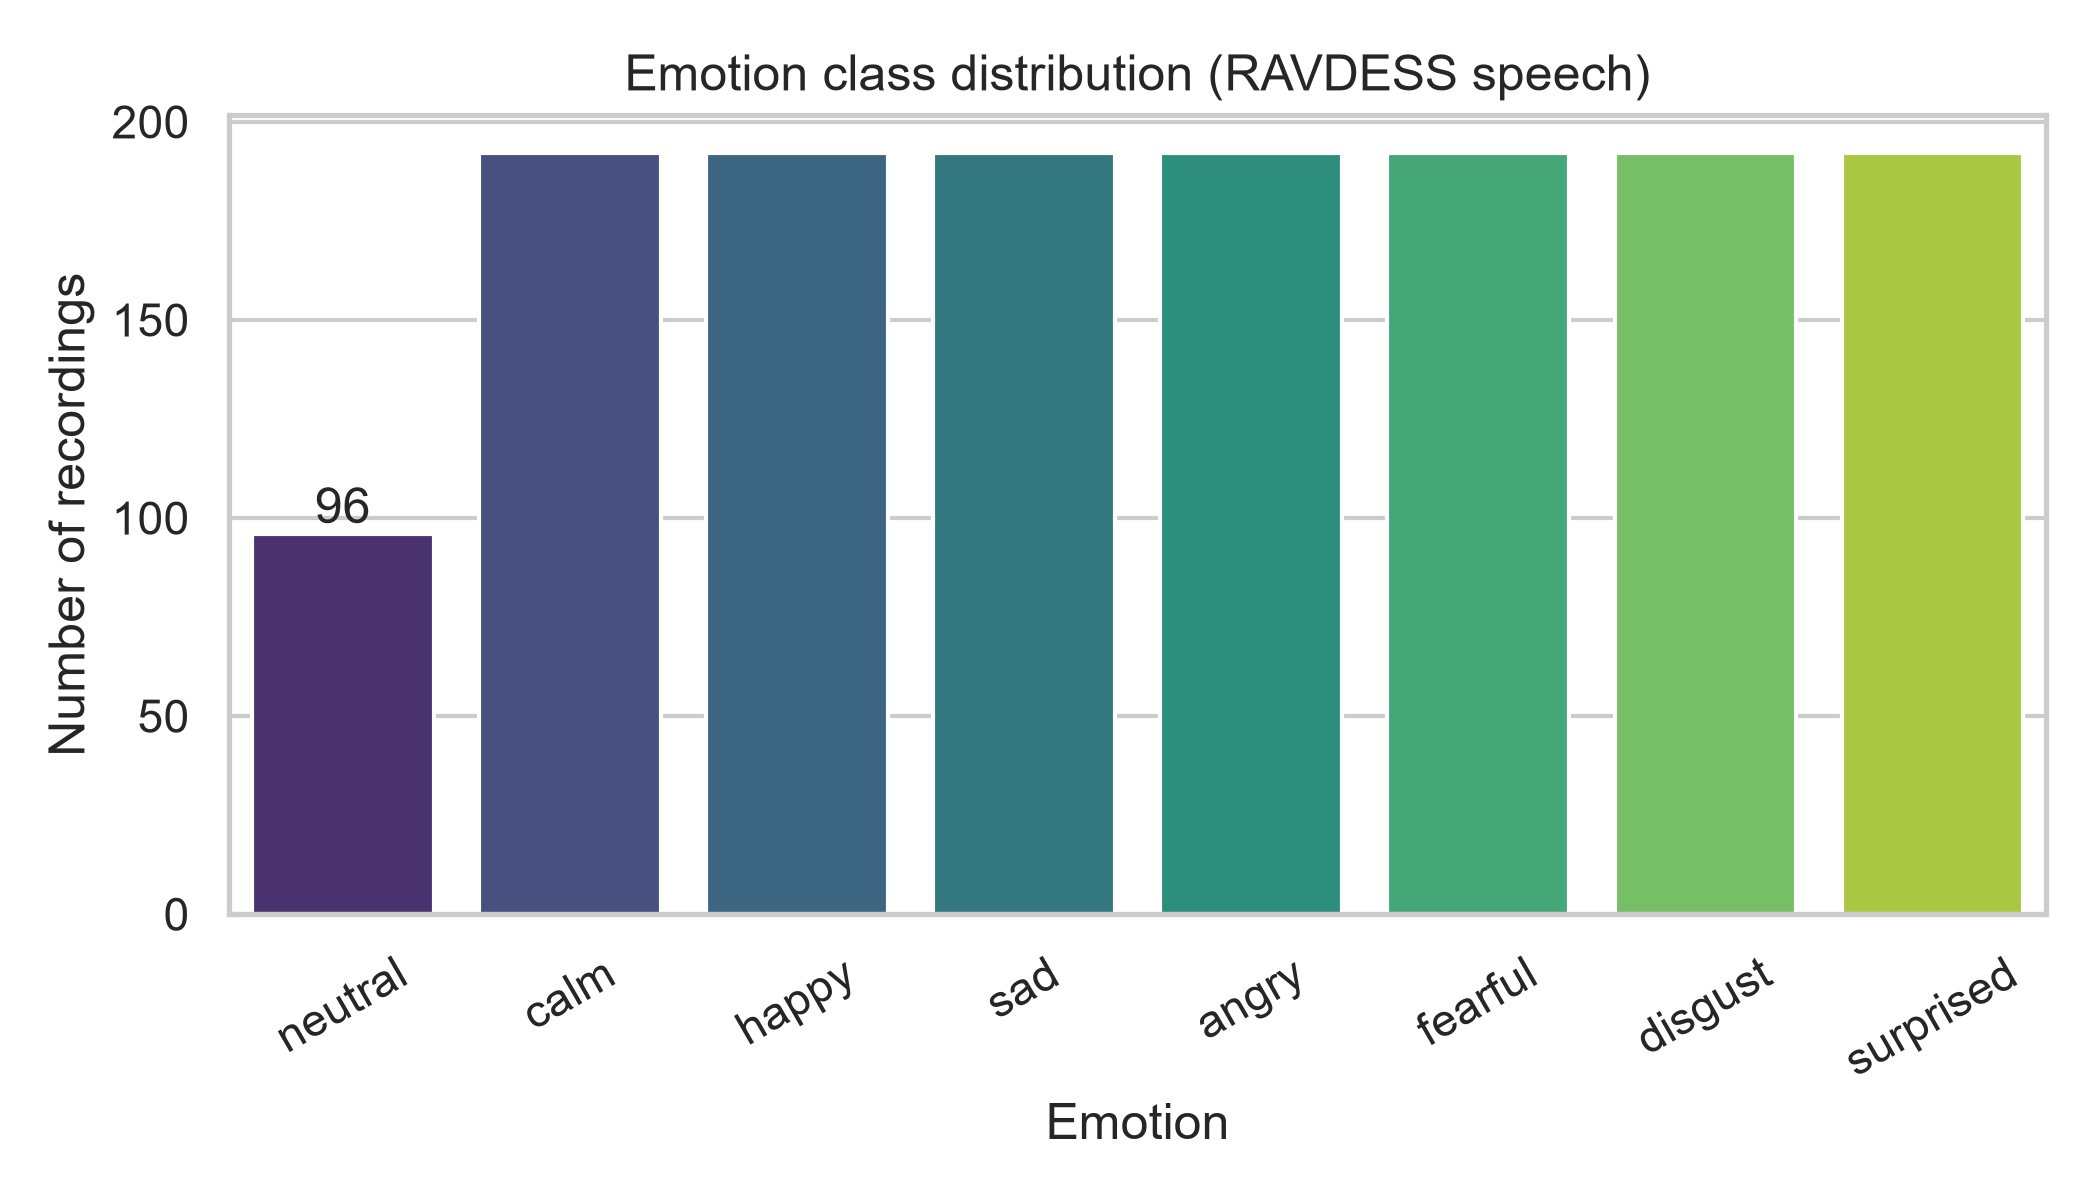

fig_split_distribution.png


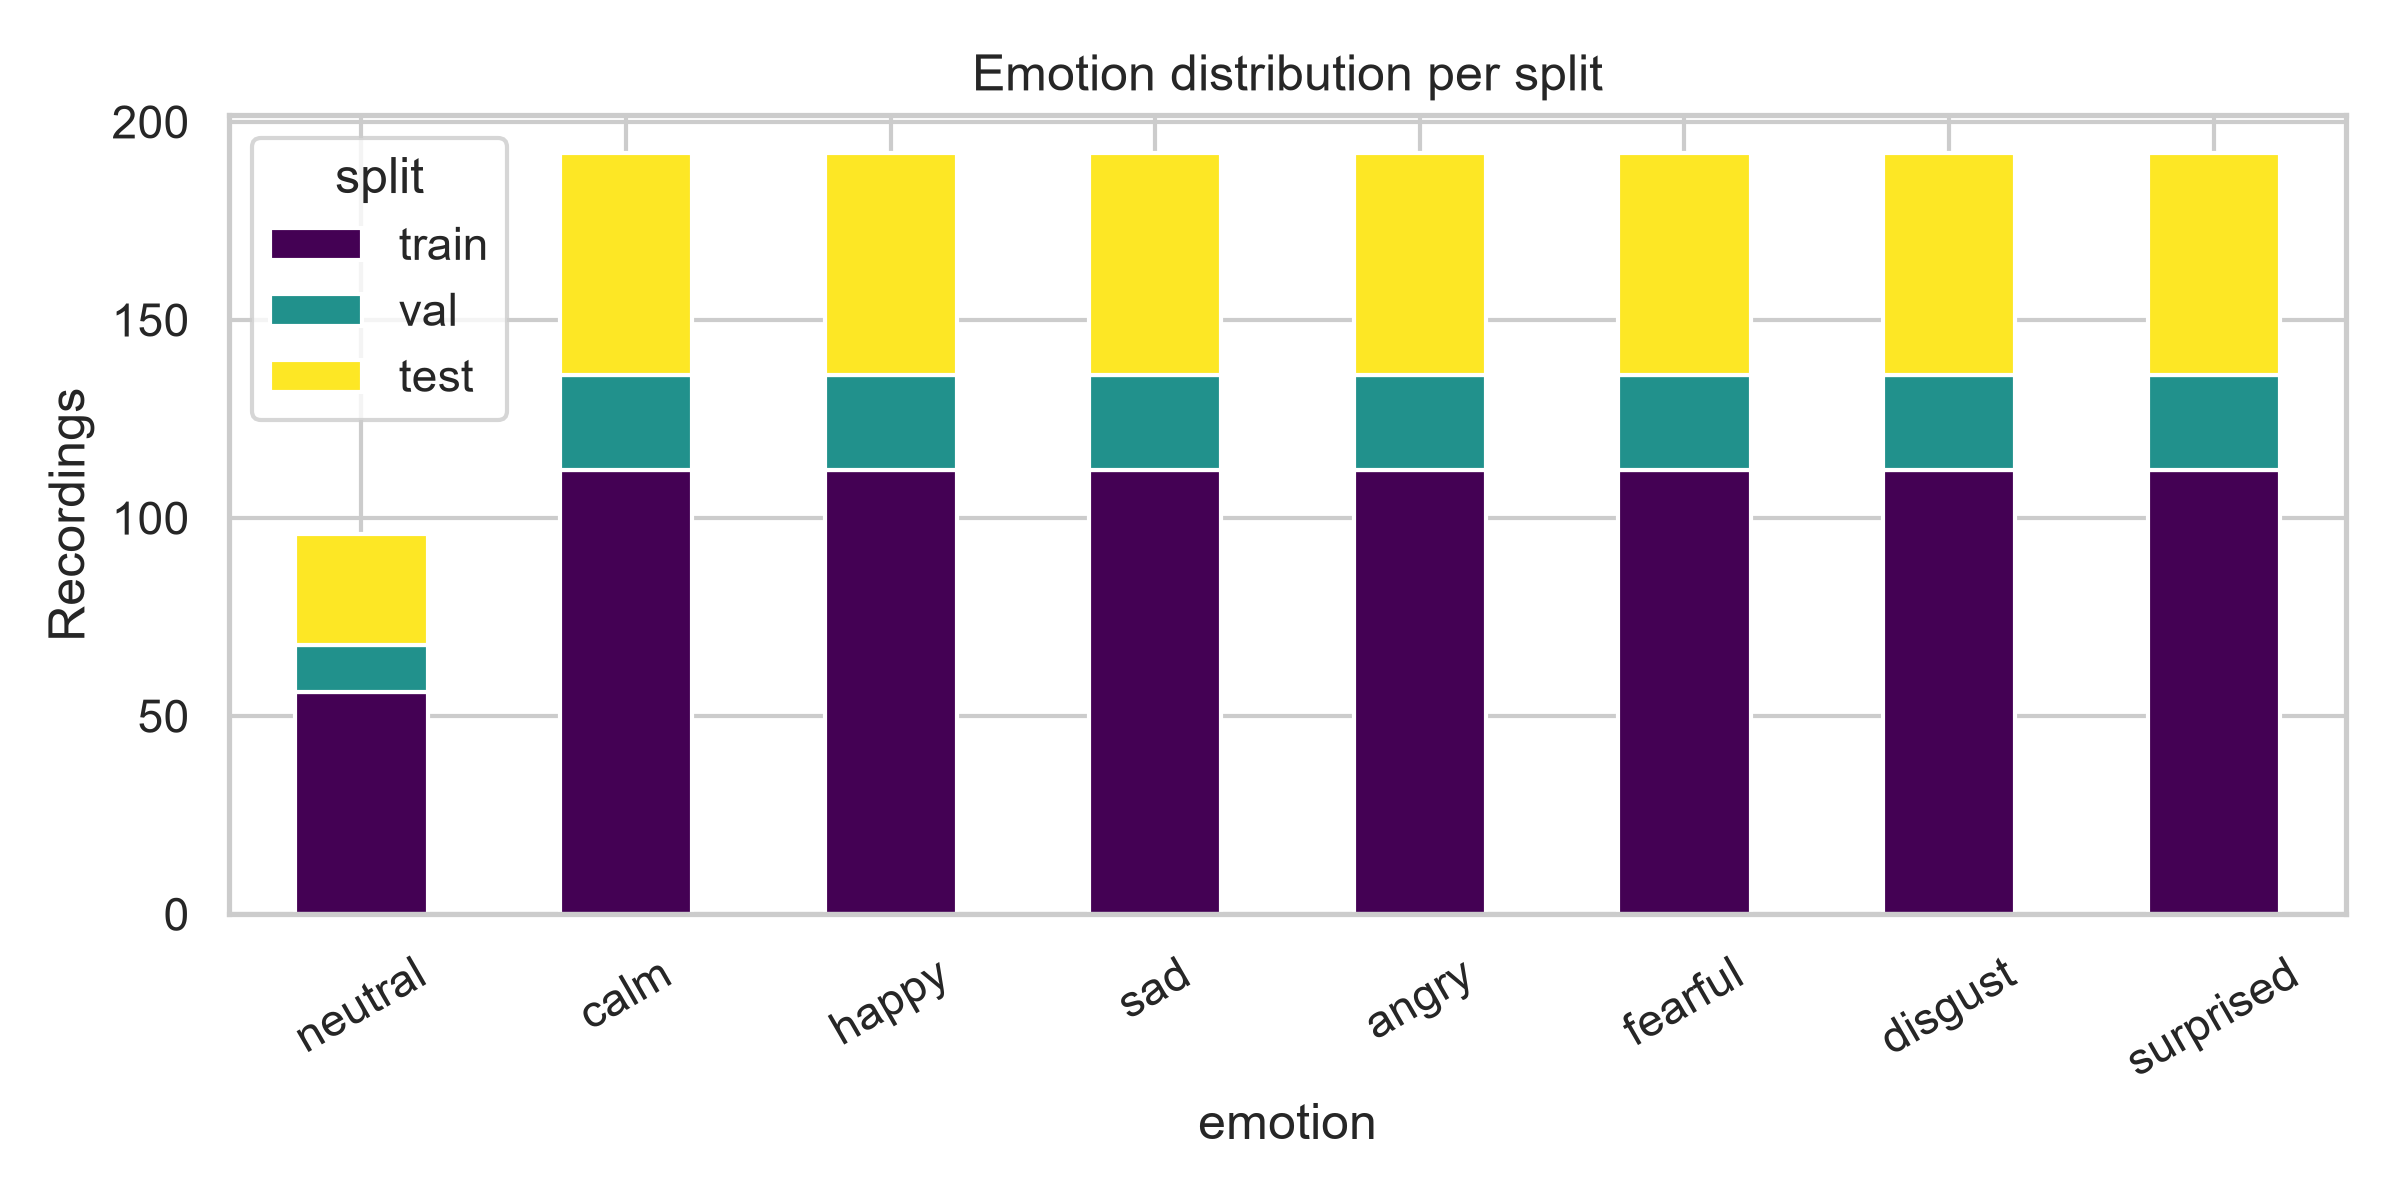

fig_gender_emotion.png


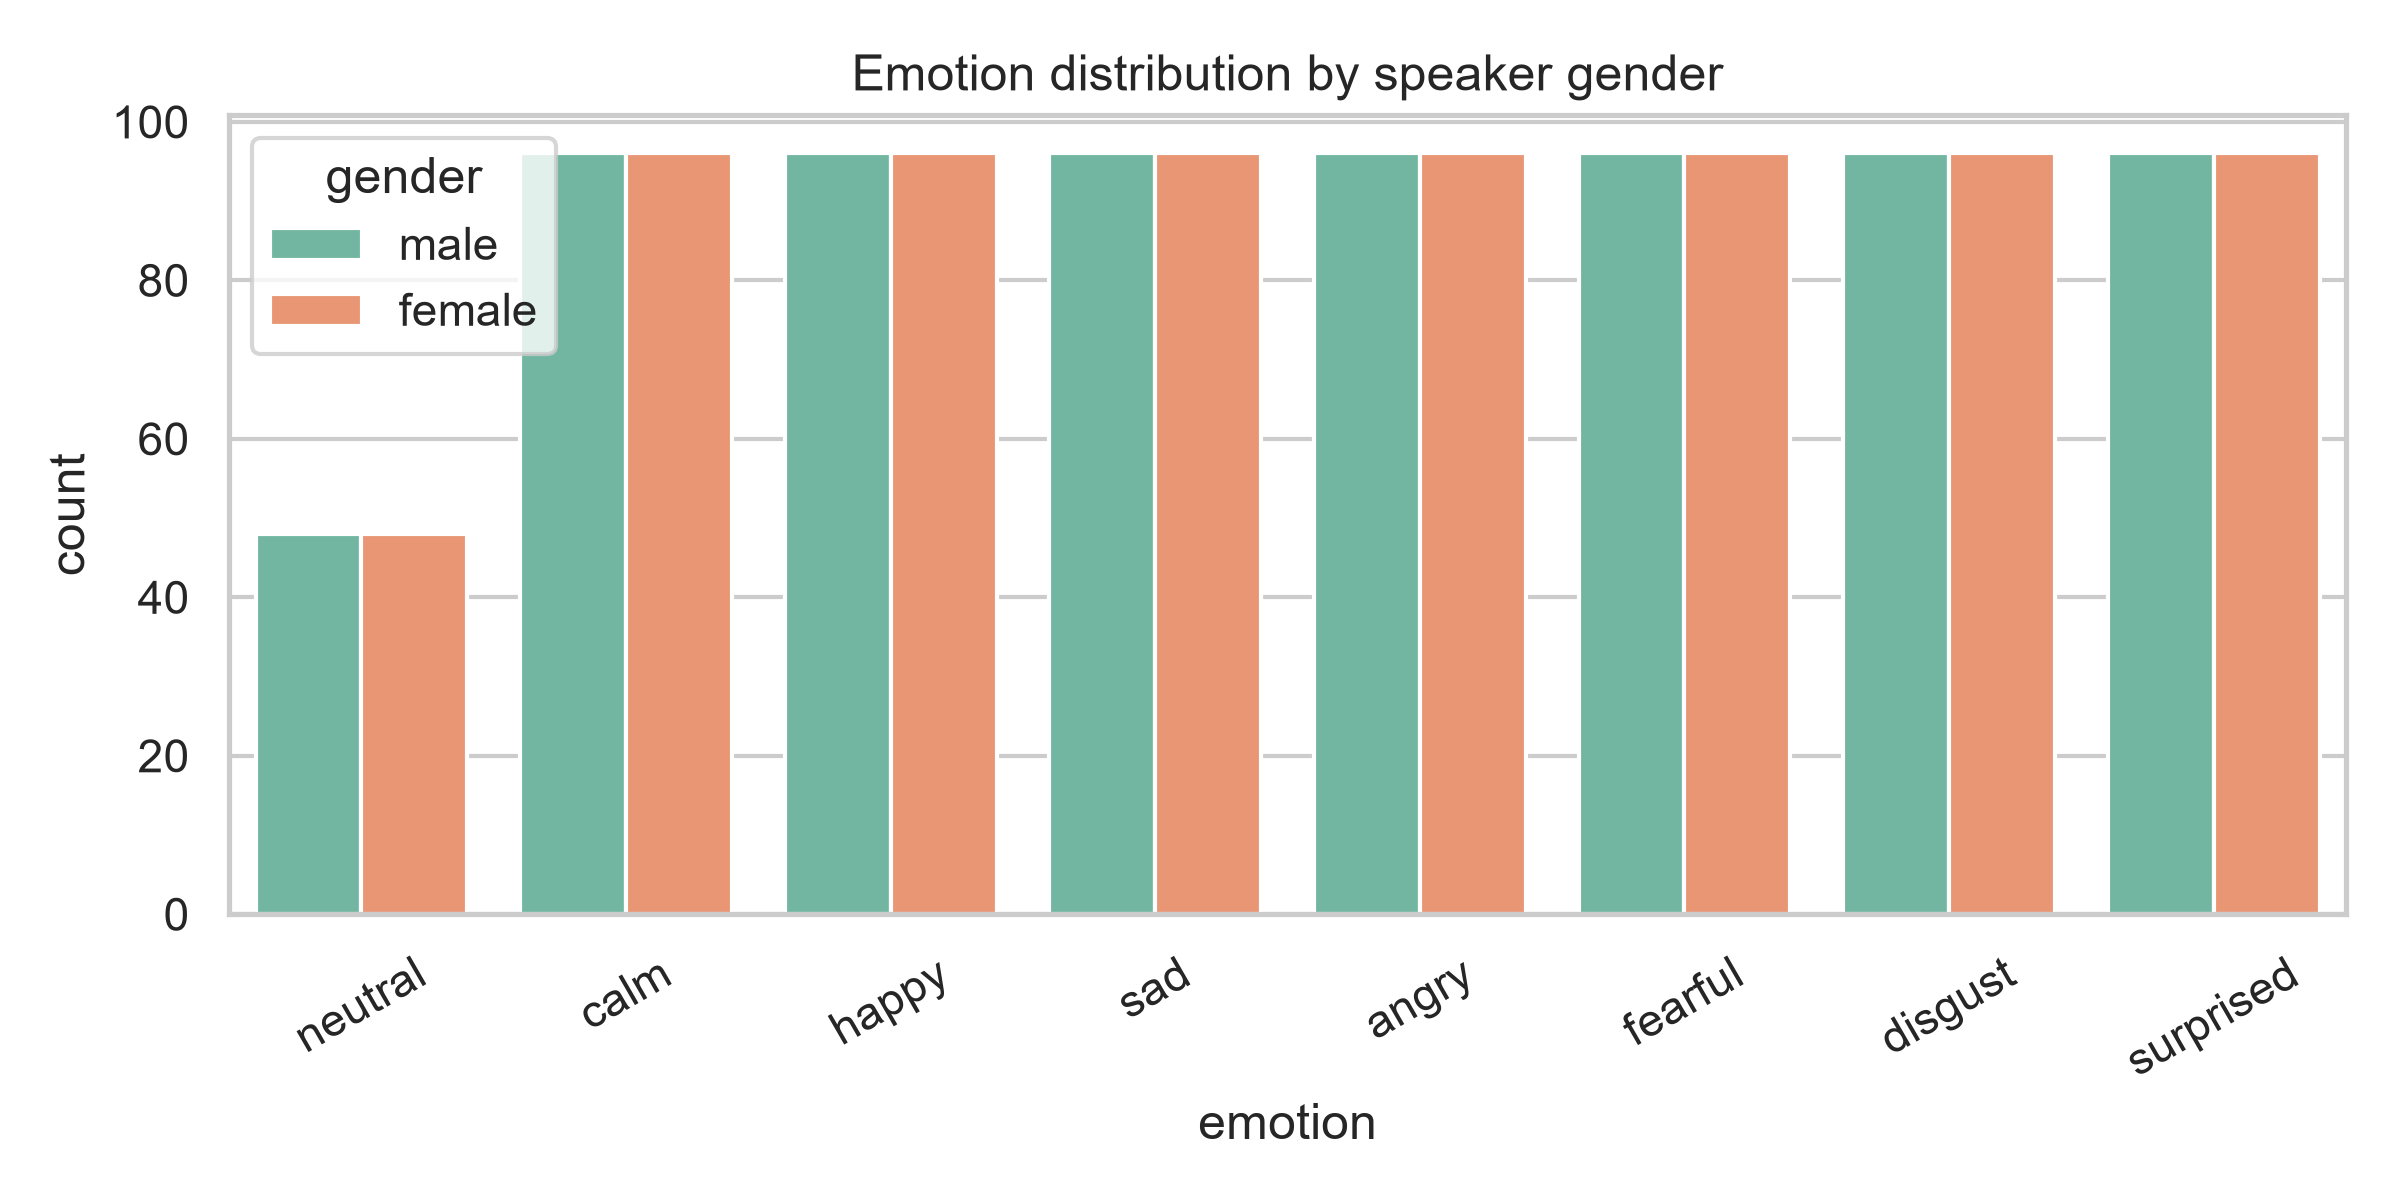

fig_duration_hist.png


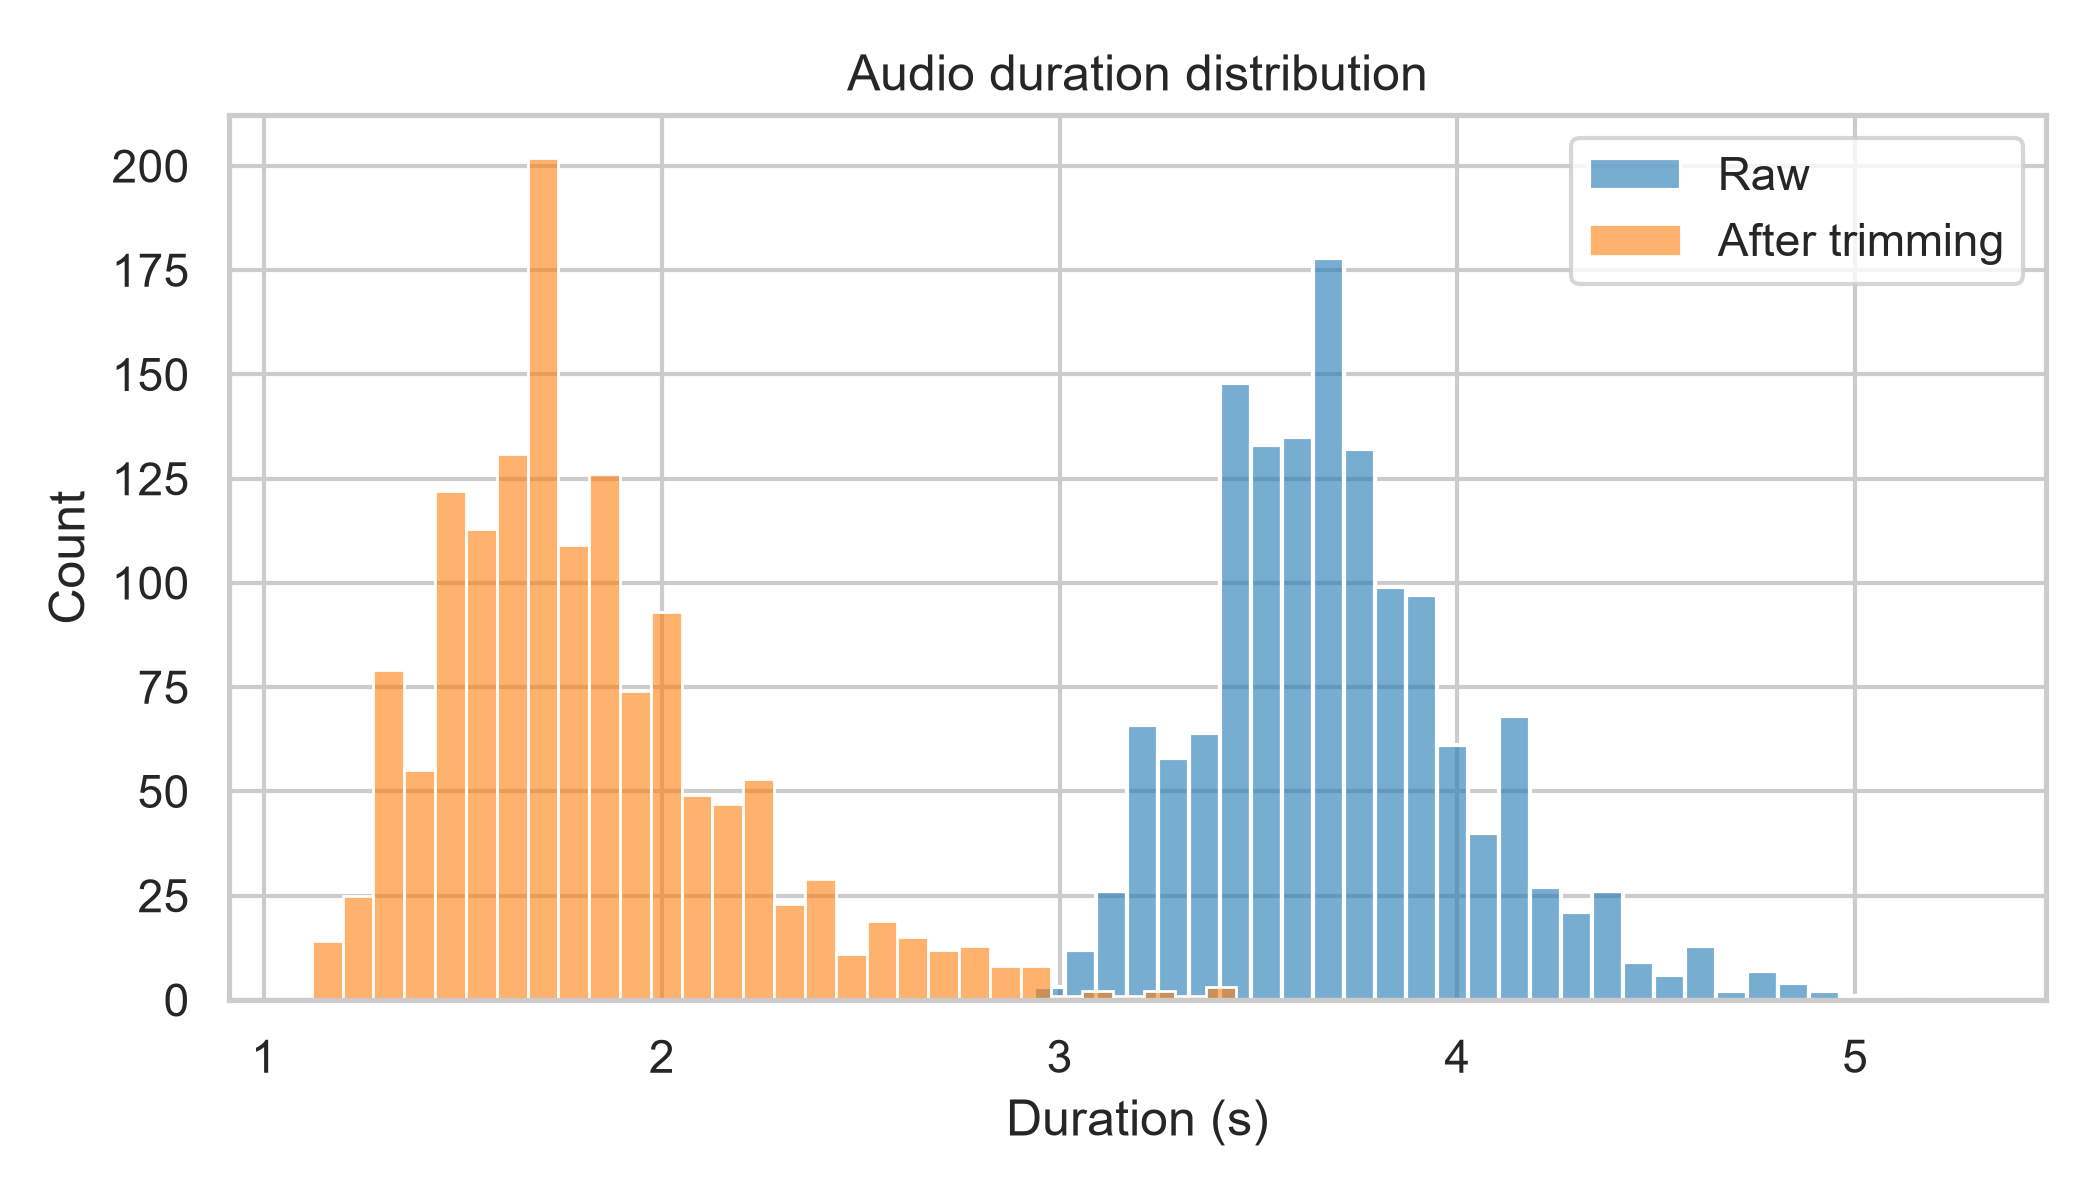

fig_duration_by_emotion.png


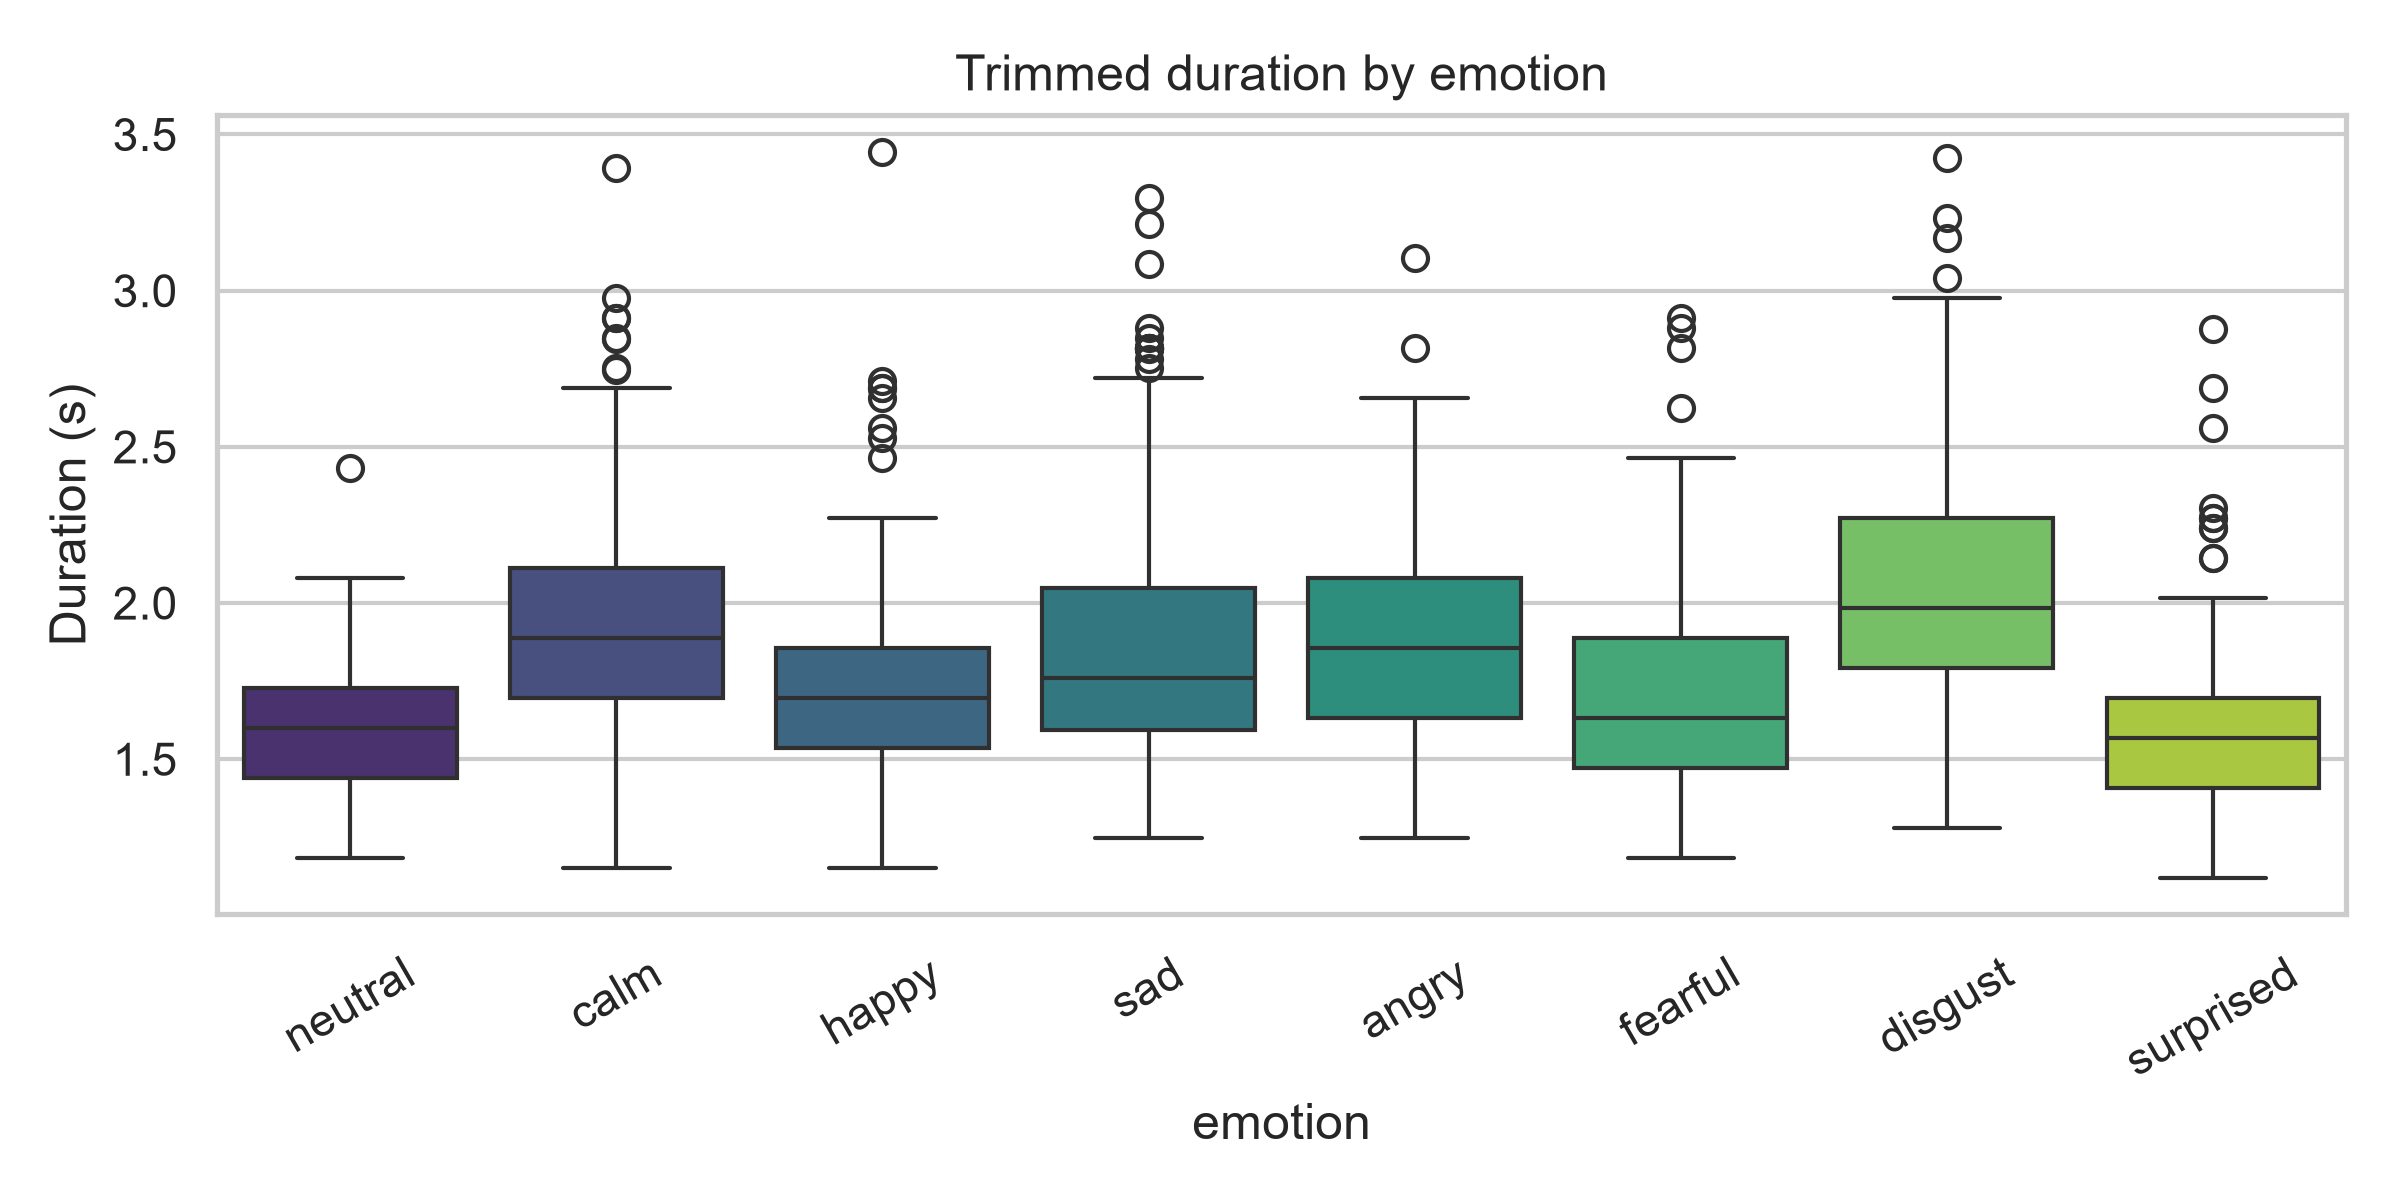

fig_mfcc_heatmap.png


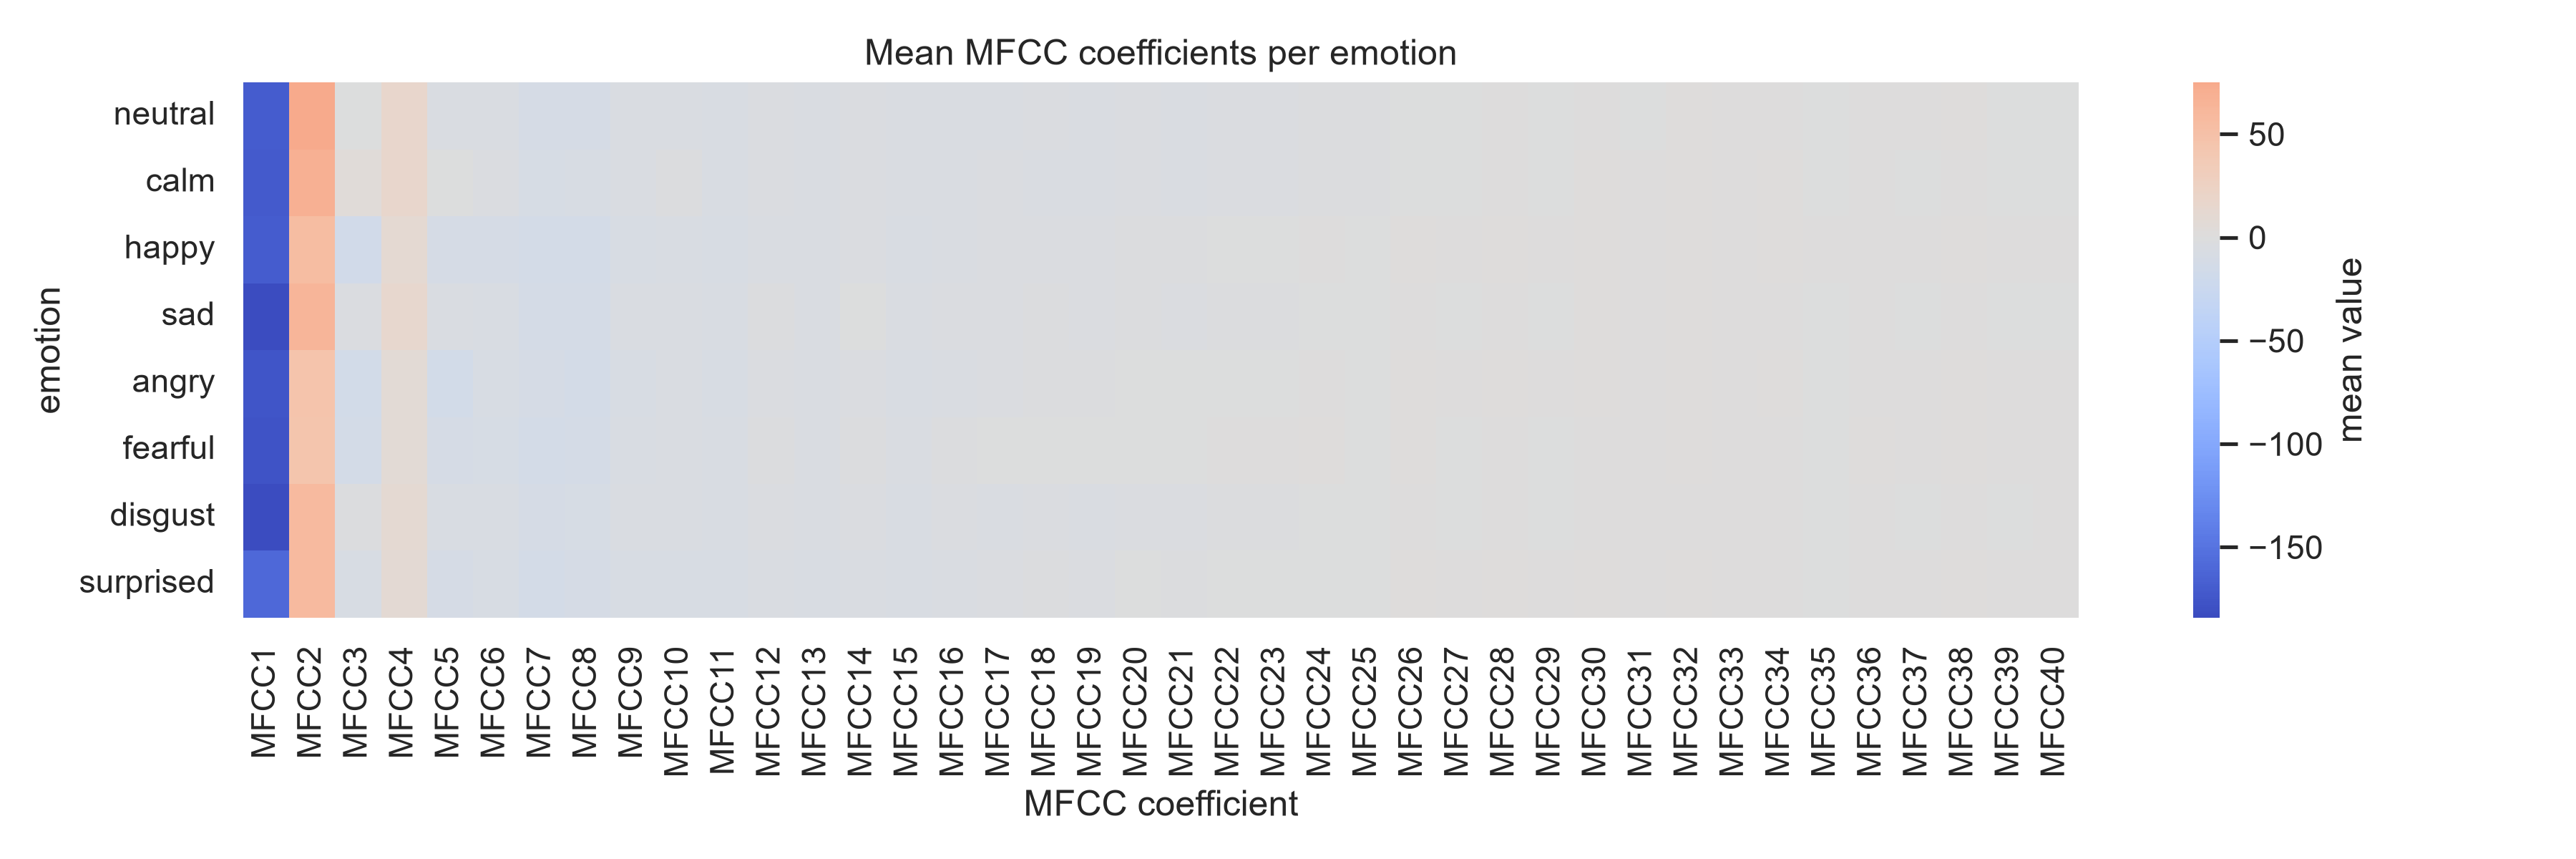

fig_mfcc_anova.png


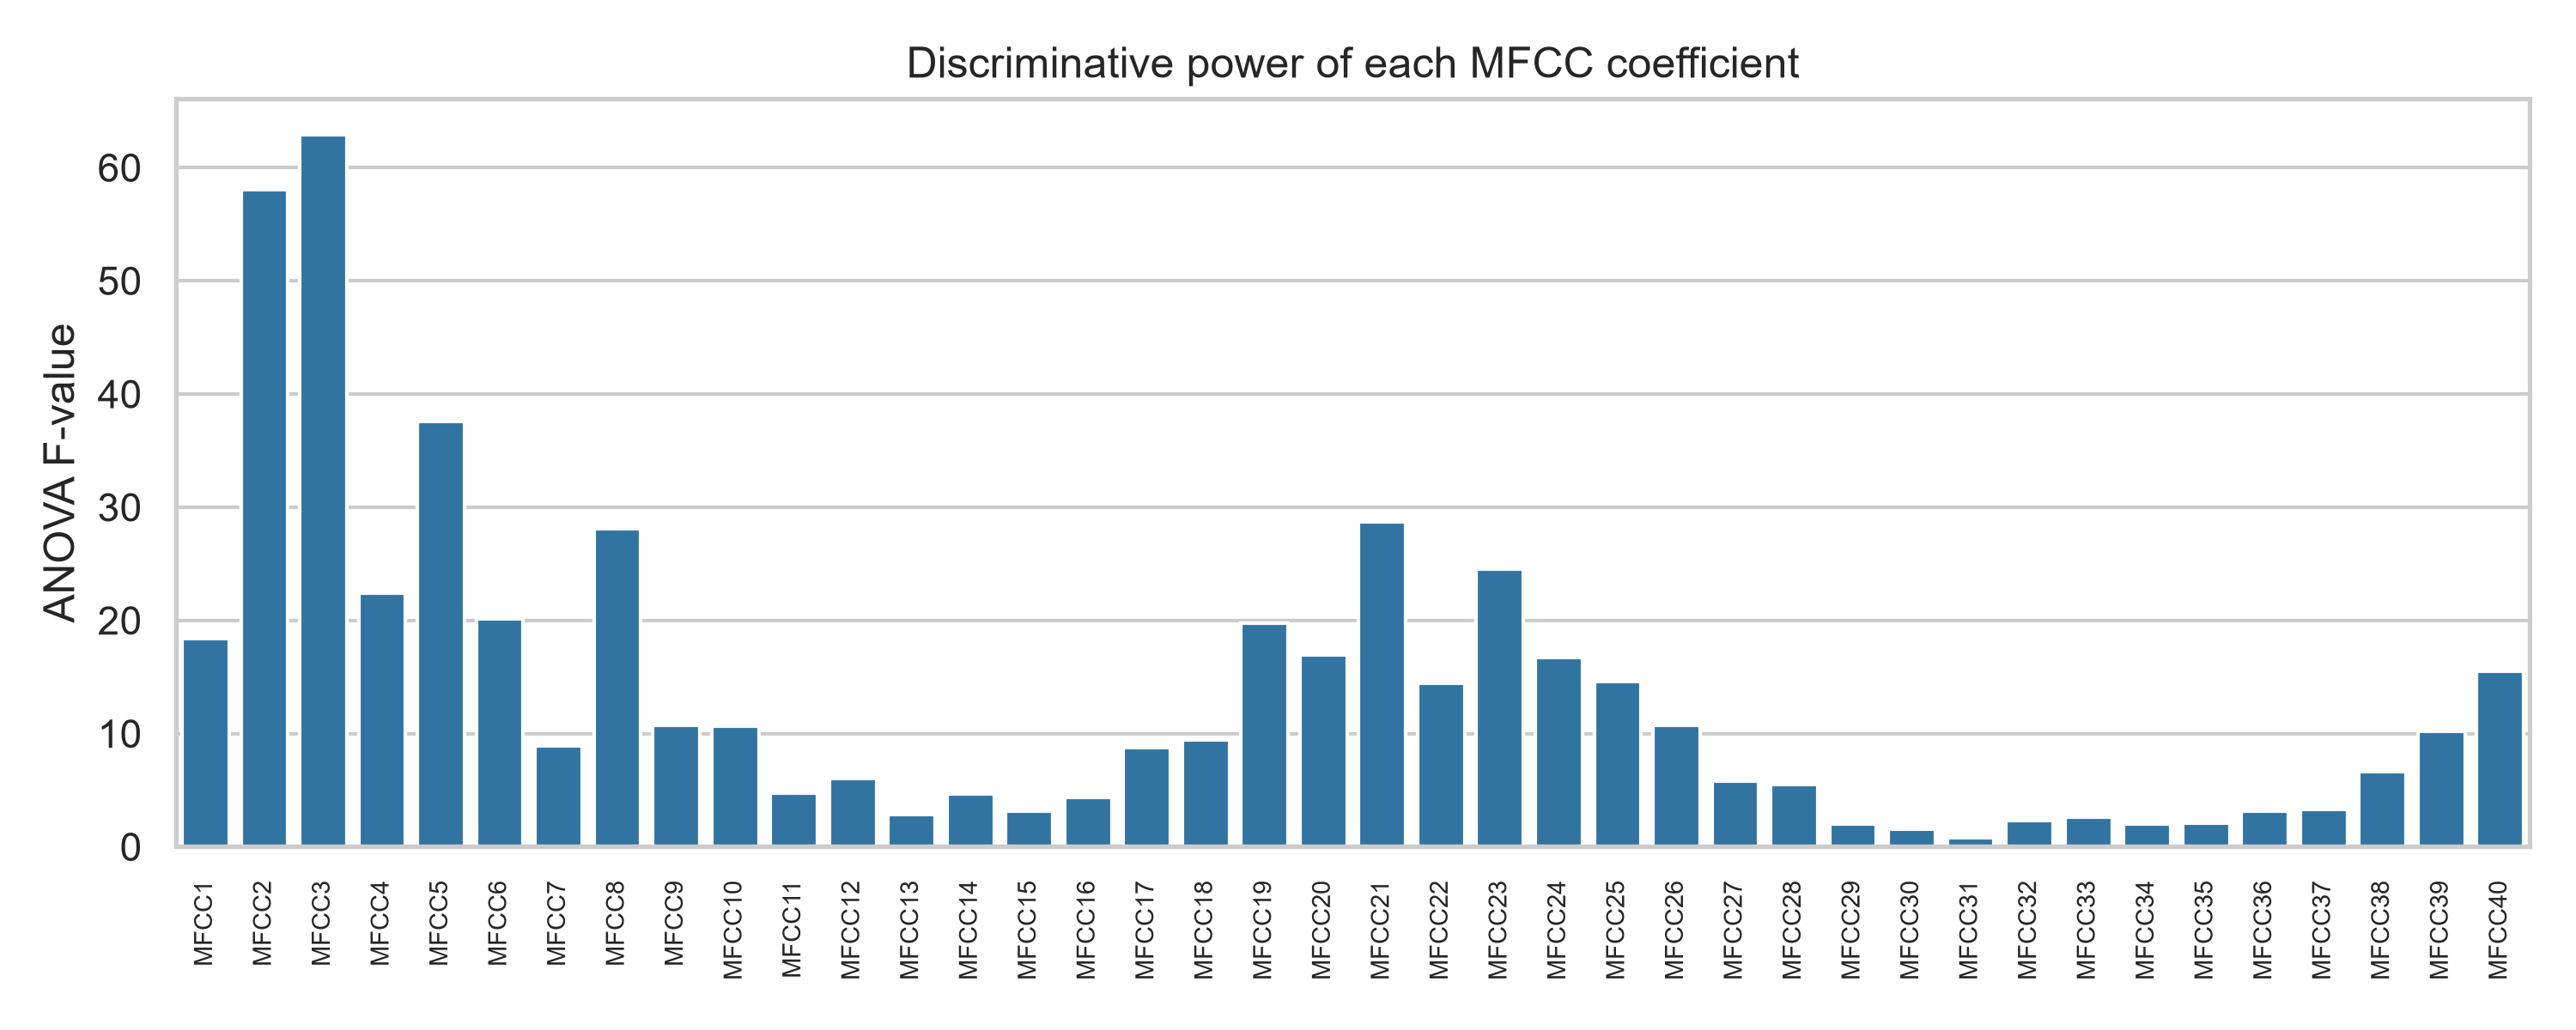

fig_mfcc_correlation.png


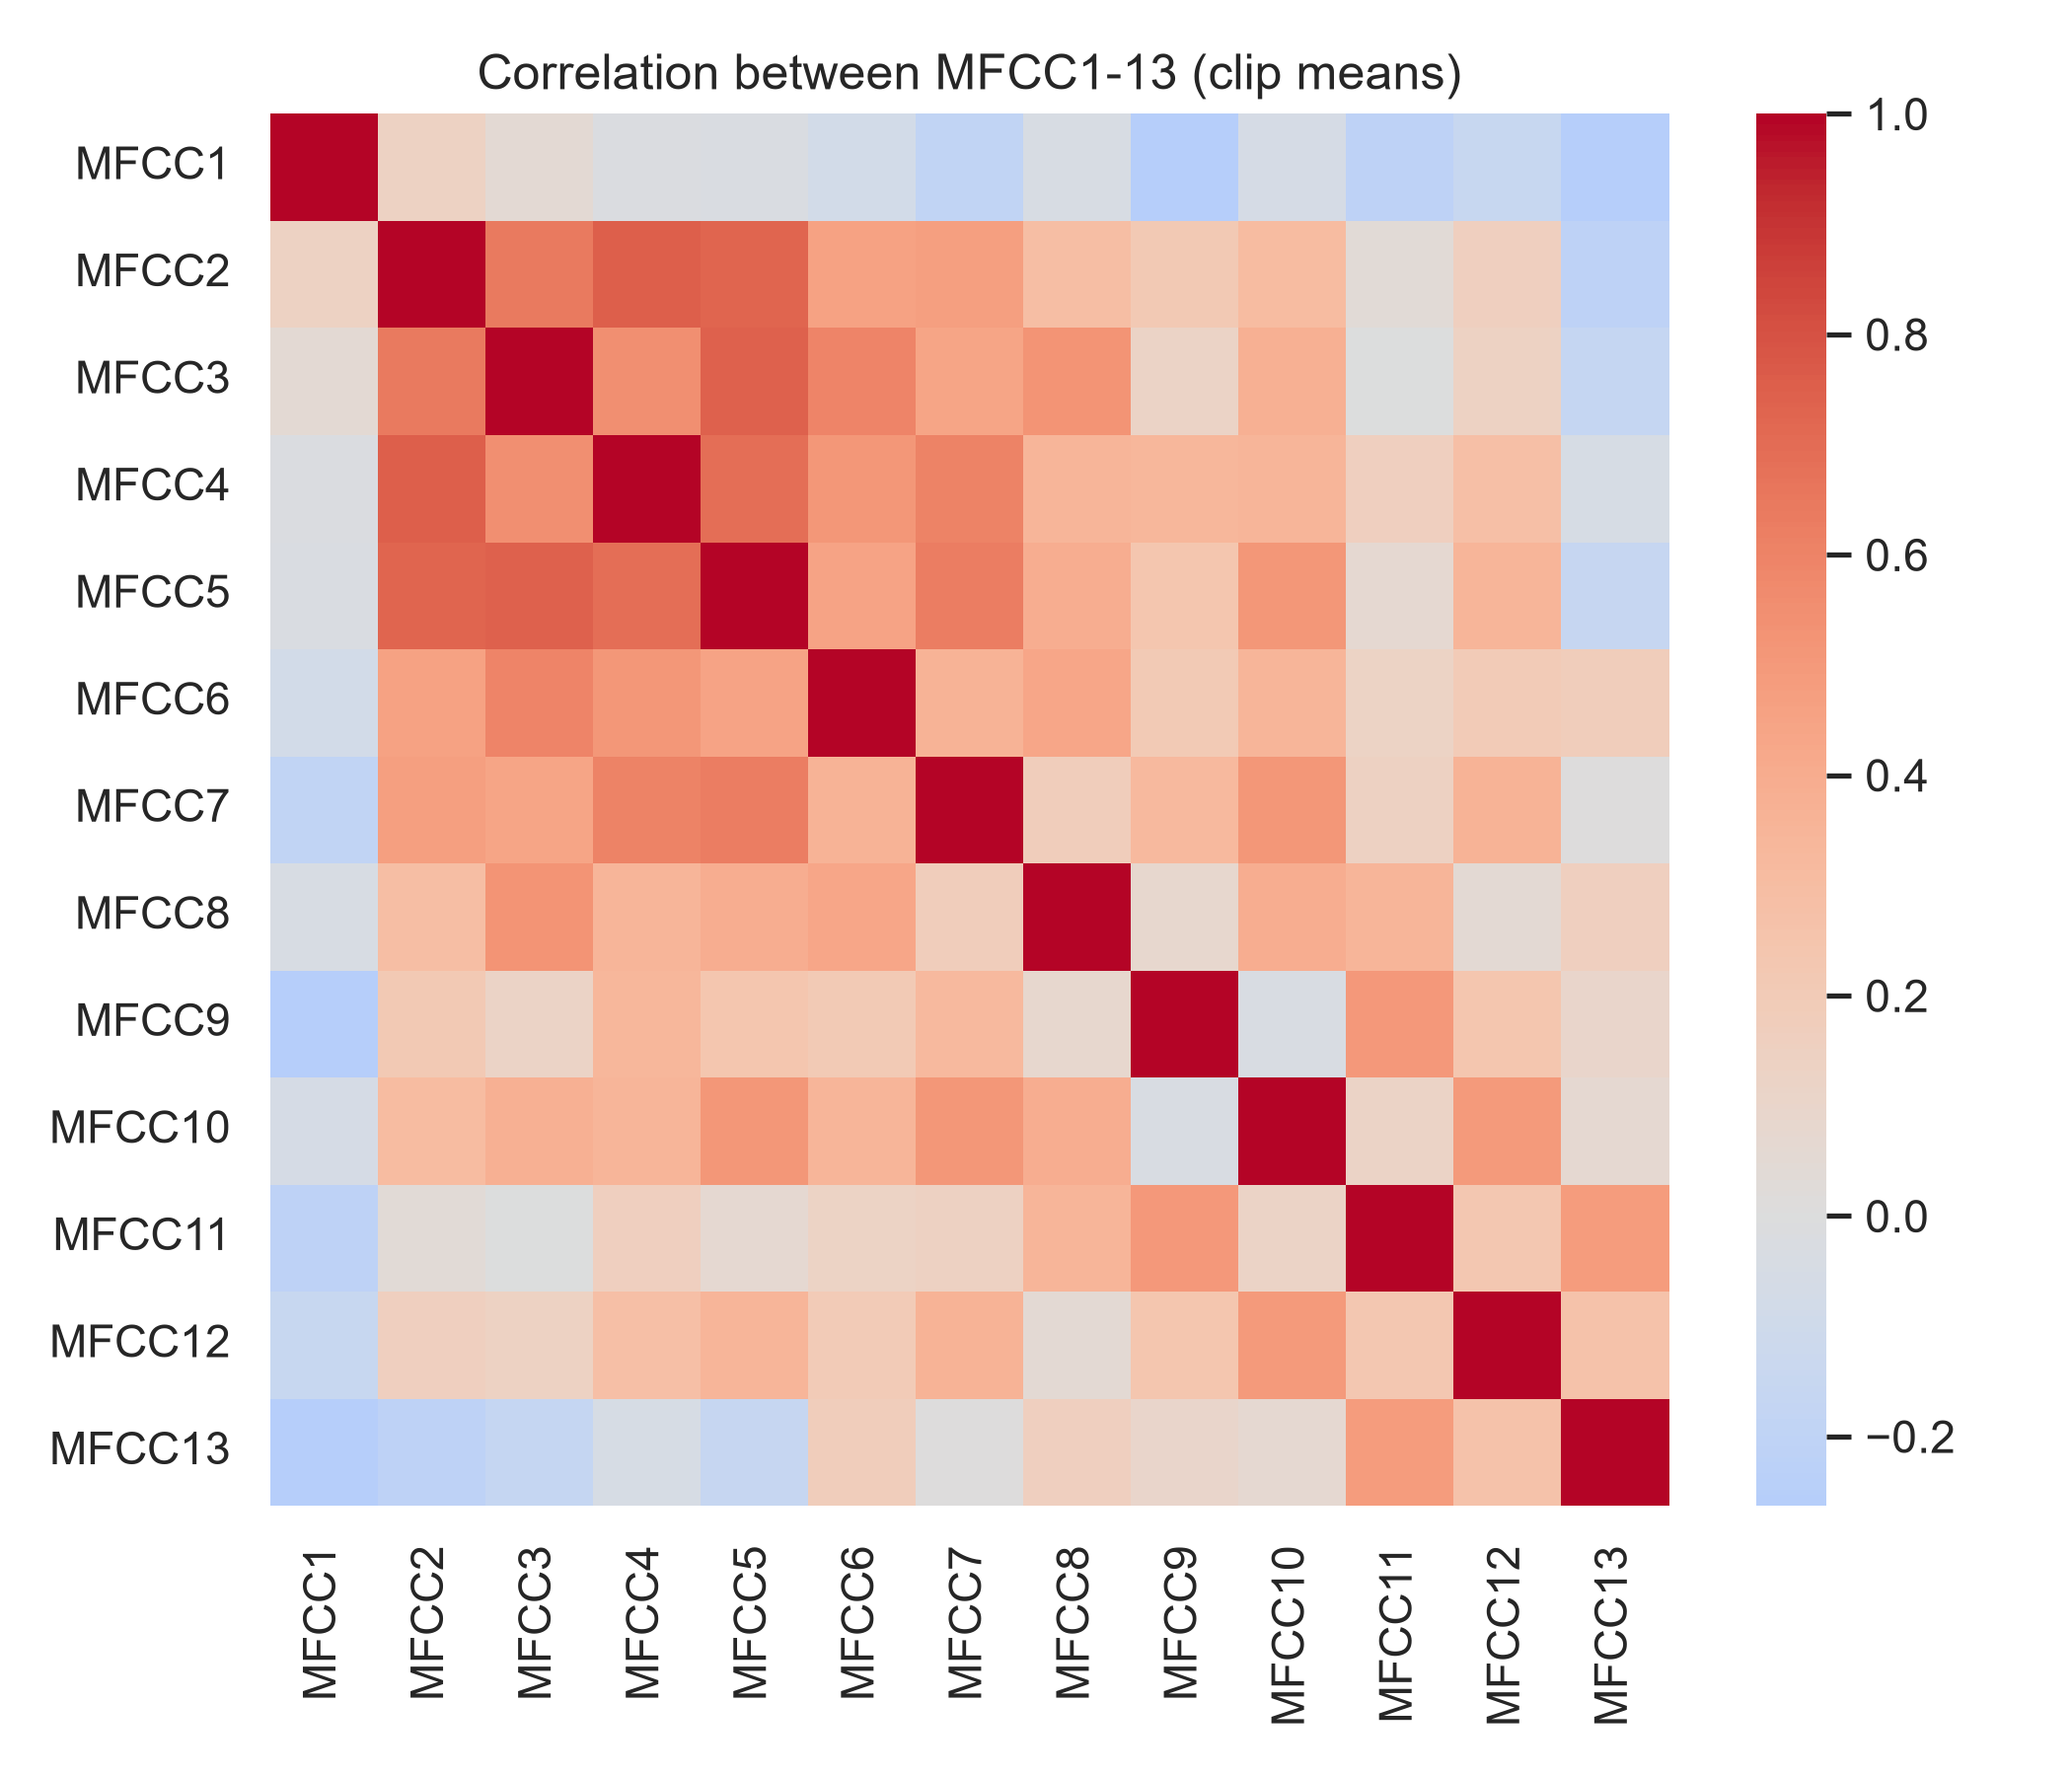

fig_pca.png


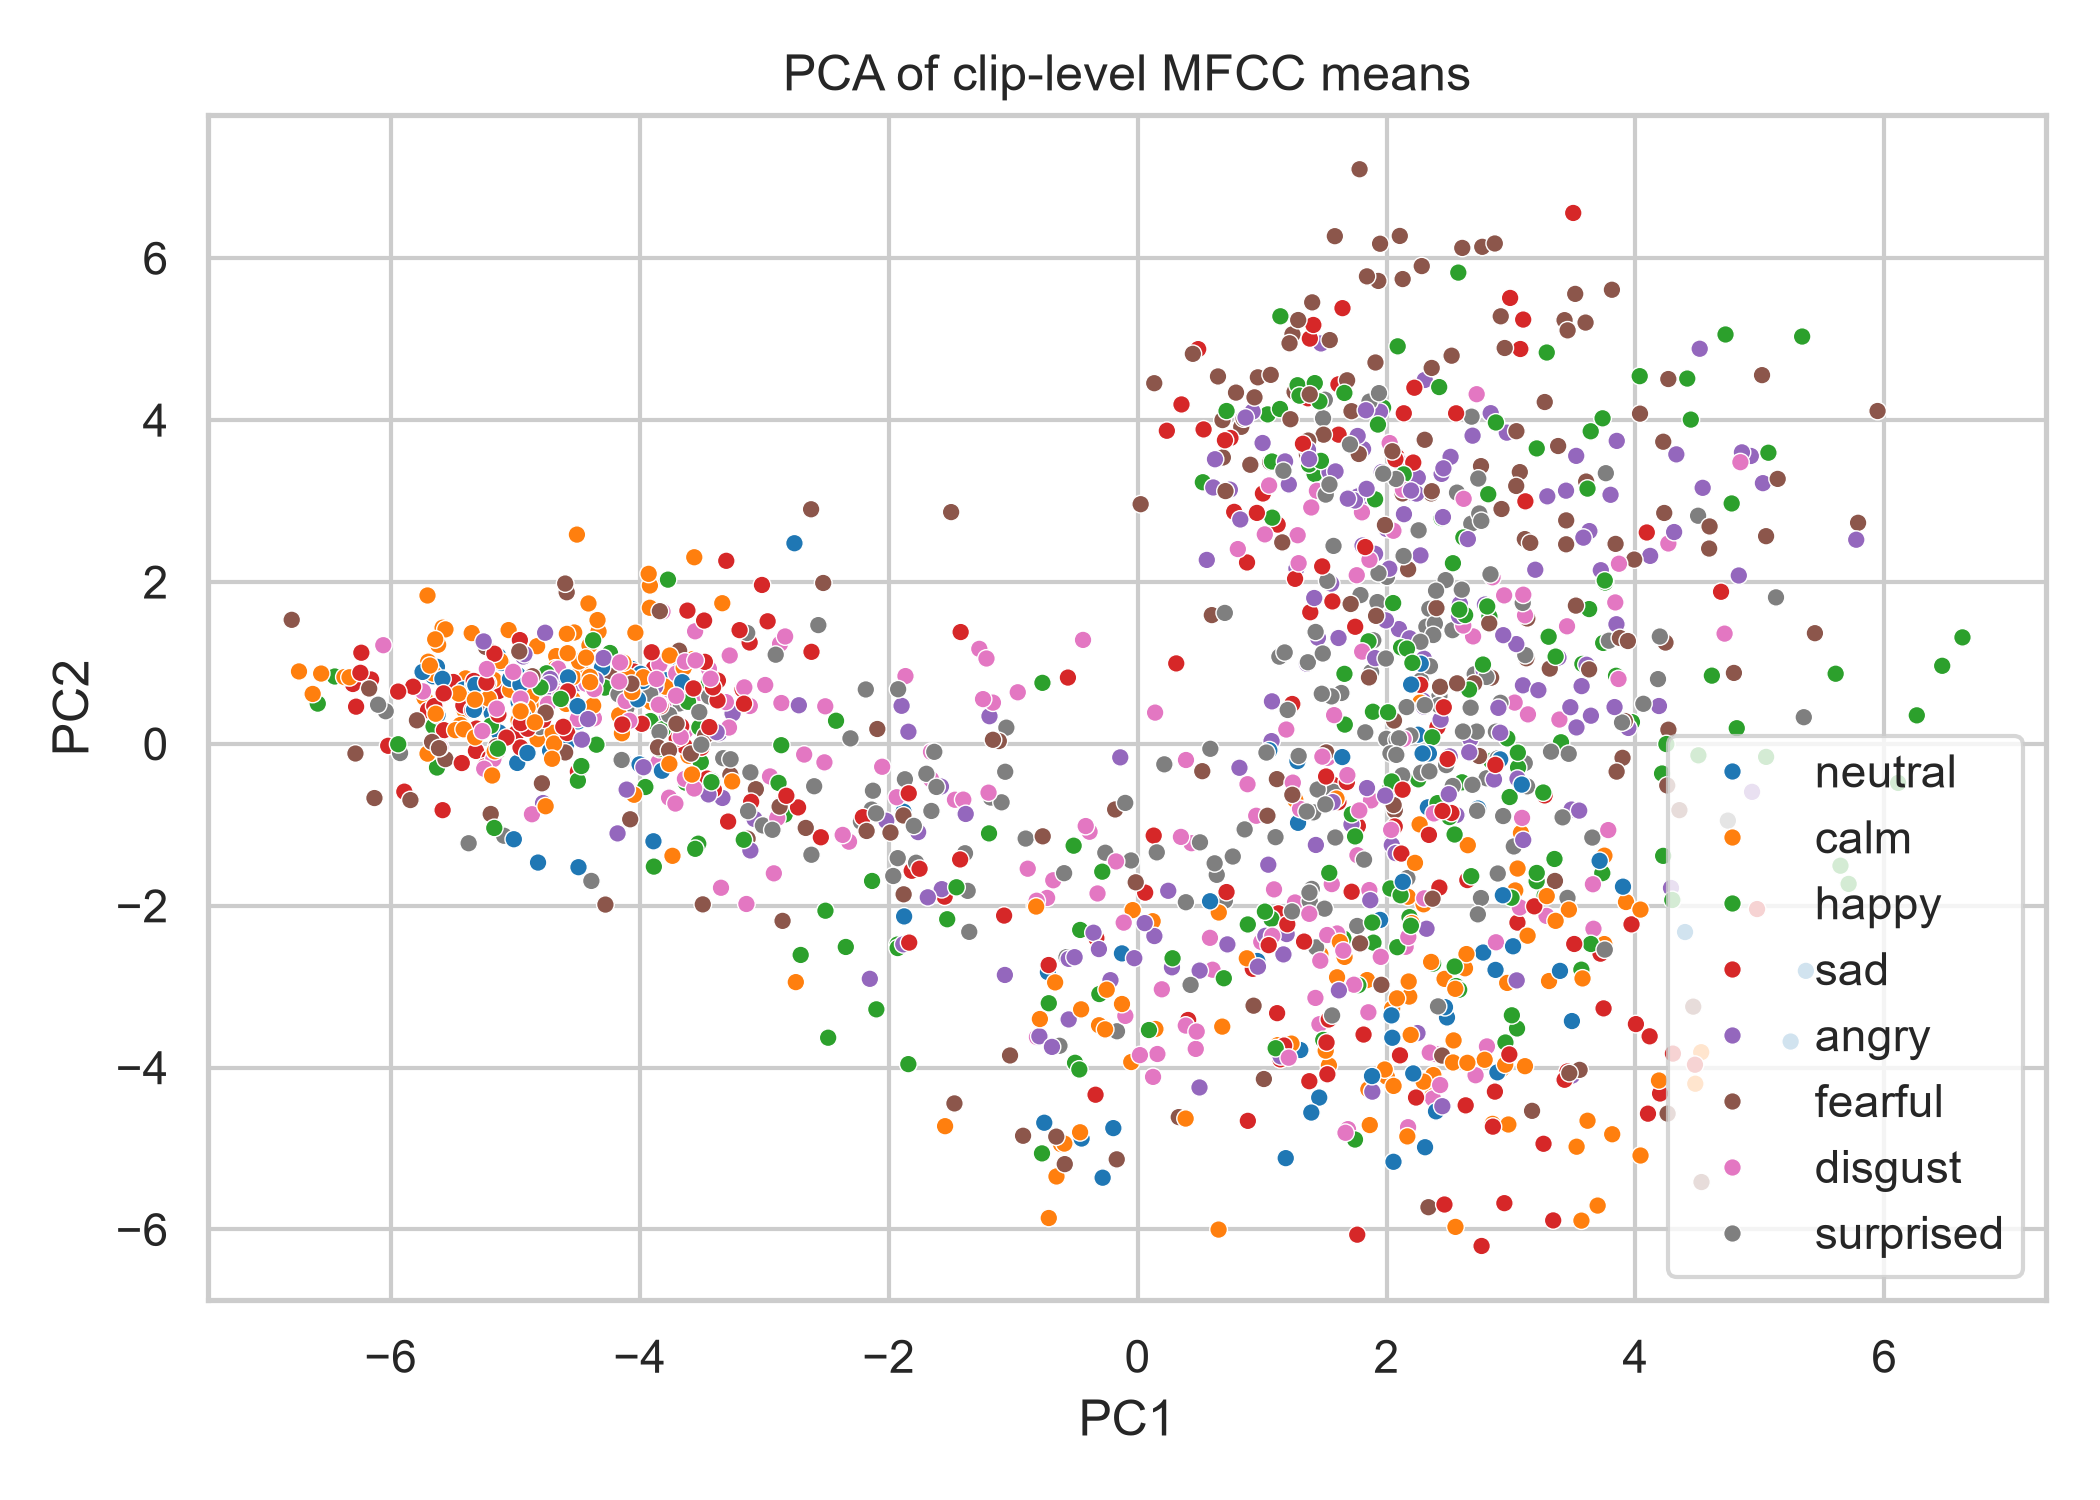

fig_examples_waveform_mfcc.png


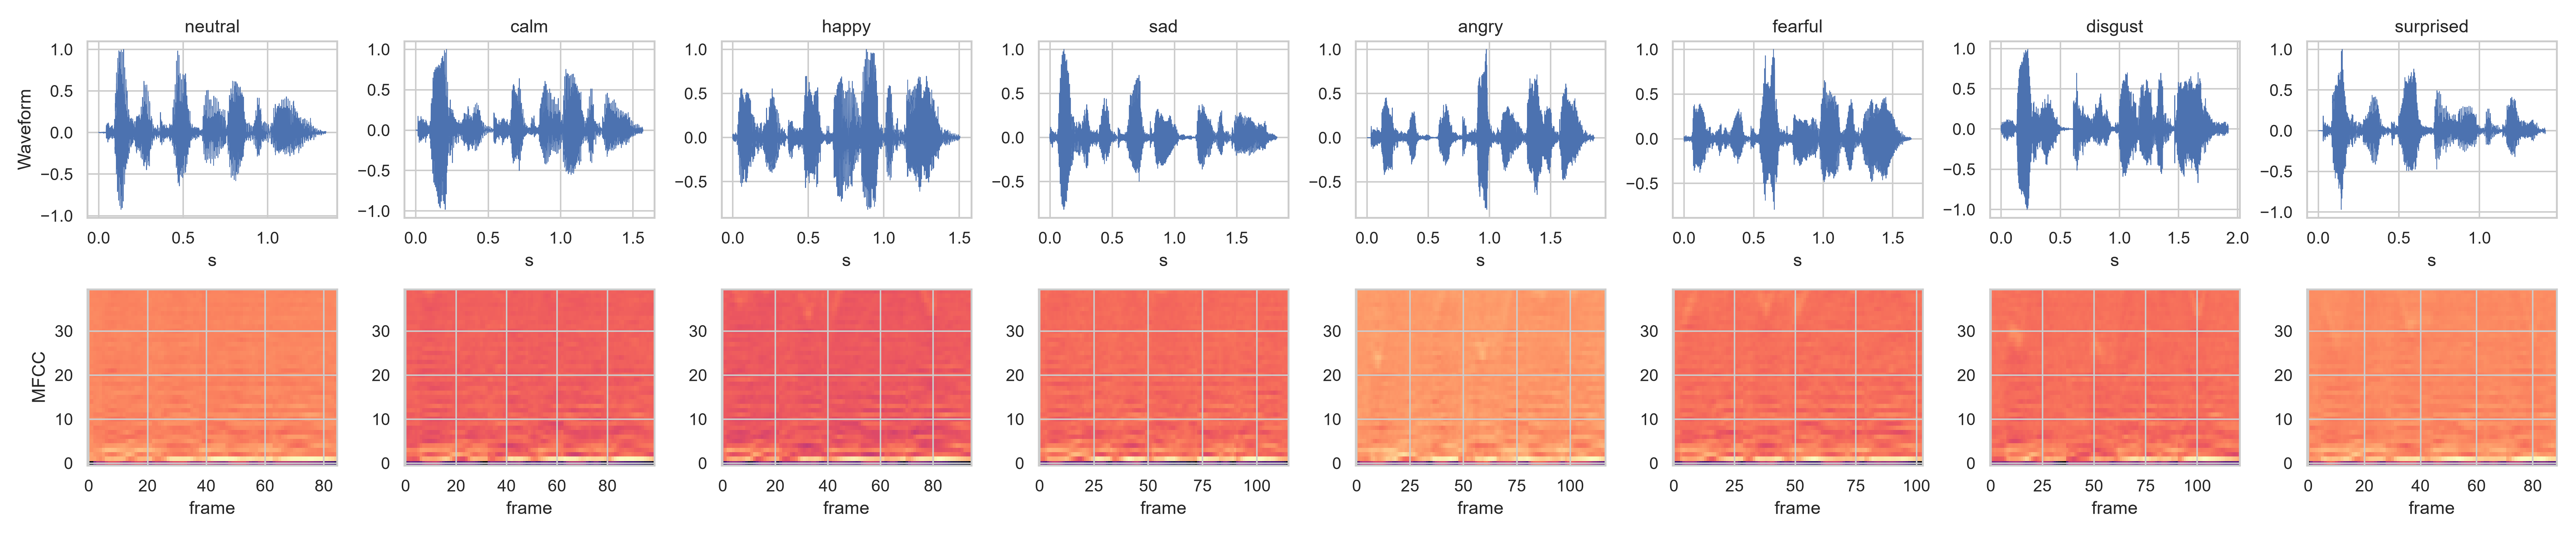

In [ ]:
from IPython.display import Image, display
for f in ["class_distribution", "split_distribution", "gender_emotion", "duration_hist",
          "duration_by_emotion", "mfcc_heatmap", "mfcc_anova", "mfcc_correlation", "pca",
          "examples_waveform_mfcc"]:
    print(f"fig_{f}.png")
    display(Image(f"output/figures/fig_{f}.png", width=750))

## 3. LSTM Model

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.feature_selection import f_classif
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")
emotions = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]

os.makedirs("output/lstm/tables", exist_ok=True)
os.makedirs("output/lstm/figures", exist_ok=True)
os.makedirs("output/lstm/models", exist_ok=True)

### 3.1 Load the features

In [ ]:
import os
import numpy as np

train = np.load("output/features/train.npz")
val = np.load("output/features/val.npz")

X_train, y_train, len_train, actors_train = train["X"], train["y"], train["lengths"], train["actors"]
X_val, y_val, len_val, actors_val = val["X"], val["y"], val["lengths"], val["actors"]

test_path = "output/features/test.npz"
if os.path.exists(test_path):
    test = np.load(test_path)
    X_test, y_test = test["X"], test["y"]
else:
    X_test, y_test = None, None

print("Train:", X_train.shape, "Validation:", X_val.shape)
if X_test is not None:
    print("Test:", X_test.shape)
else:
    print("Test split unavailable (empty fallback used).")

Train: (840, 161, 40) Validation: (180, 161, 40)
Test: (420, 161, 40)


### 3.2 Build and train the LSTM

In [ ]:
def build_lstm(n_steps, n_features, units=128, n_layers=1, dropout=0.3,
               learning_rate=0.001, bidirectional=False):
    inputs = keras.Input(shape=(n_steps, n_features))
    x = layers.Masking(mask_value=0.0)(inputs)
    for i in range(n_layers):
        lstm = layers.LSTM(units, return_sequences=(i < n_layers - 1))
        if bidirectional:
            x = layers.Bidirectional(lstm)(x)
        else:
            x = lstm(x)
        x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(8, activation="softmax")(x)

    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def get_class_weights(y):
    counts = np.bincount(y, minlength=8)
    return {i: len(y) / (8 * counts[i]) for i in range(8)}


def train_lstm(params, X_tr, y_tr, X_va, y_va):
    tf.keras.utils.set_random_seed(42)
    model = build_lstm(X_tr.shape[1], X_tr.shape[2], params["units"], params["n_layers"],
                       params["dropout"], params["learning_rate"], params["bidirectional"])
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                               restore_best_weights=True)
    history = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=100,
                        batch_size=params["batch_size"], class_weight=get_class_weights(y_tr),
                        callbacks=[early_stop], verbose=0)
    return model, history.history


def evaluate(model, X, y):
    y_pred = model.predict(X, verbose=0).argmax(axis=1)
    scores = {"Accuracy": accuracy_score(y, y_pred),
              "Precision": precision_score(y, y_pred, average="macro", zero_division=0),
              "Recall": recall_score(y, y_pred, average="macro", zero_division=0),
              "F1-score": f1_score(y, y_pred, average="macro", zero_division=0)}
    return scores, y_pred


def plot_history(history, title, file_name):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history["loss"], label="Training")
    axes[0].plot(history["val_loss"], label="Validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
    axes[1].plot(history["accuracy"], label="Training")
    axes[1].plot(history["val_accuracy"], label="Validation")
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
    axes[0].legend(); axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(f"output/lstm/figures/{file_name}", dpi=300)
    plt.show()

### 3.3 Baseline model (default parameters, all 40 MFCCs)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 161, 40)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 161, 40)   │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masking (Masking)   │ (None, 161, 40)   │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any (Any)           │ (None, 161)       │          0 │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 128)       │     86,528 │ masking[0][0],    │
│                     │                   │            │ any[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 8)         │        520 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 285,914 (1.09 MB)

 Trainable params: 95,304 (372.28 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 190,610 (744.57 KB)

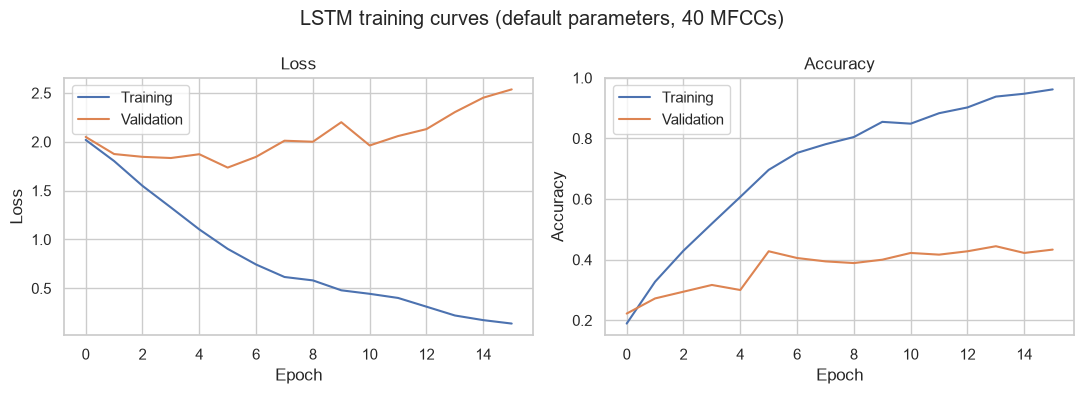

,Set,Accuracy,Precision,Recall,F1-score,Epochs
0,Train,0.8119,0.8086,0.8237,0.8097,16
1,Validation,0.4278,0.4549,0.4271,0.4236,16
2,Test,0.4119,0.4254,0.4174,0.4051,16


In [ ]:
default_params = {"units": 128, "n_layers": 1, "dropout": 0.3,
                  "learning_rate": 0.001, "batch_size": 32, "bidirectional": False}

model, history = train_lstm(default_params, X_train, y_train, X_val, y_val)
model.summary()
plot_history(history, "LSTM training curves (default parameters, 40 MFCCs)",
             "fig_lstm_baseline_curves.png")

rows = []
for name, X, y in [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    scores, _ = evaluate(model, X, y)
    rows.append({"Set": name, **scores})
baseline_results = pd.DataFrame(rows).round(4)
baseline_results["Epochs"] = len(history["loss"])
baseline_results.to_csv("output/lstm/tables/table_lstm_baseline_results.csv", index=False)
baseline_results

### 3.4 Hyperparameter tuning

In [ ]:
search_space = {"units": [32, 64, 128, 256],
                "n_layers": [1, 2],
                "dropout": [0.1, 0.3, 0.5],
                "learning_rate": [0.01, 0.001, 0.0001],
                "batch_size": [16, 32, 64],
                "bidirectional": [False, True]}

best_params = dict(default_params)
rows = []
for param, values in search_space.items():
    val_accs = []
    for value in values:
        params = dict(best_params)
        params[param] = value
        model, history = train_lstm(params, X_train, y_train, X_val, y_val)
        scores, _ = evaluate(model, X_val, y_val)
        val_accs.append(scores["Accuracy"])
        rows.append({"Parameter": param, "Value": str(value), "Val_accuracy": scores["Accuracy"],
                     "Val_F1": scores["F1-score"], "Epochs": len(history["loss"])})
        print(f"{param} = {value}: validation accuracy = {scores['Accuracy']:.4f}")
    best_params[param] = values[int(np.argmax(val_accs))]
    print(f"Best {param} = {best_params[param]}")

tuning_results = pd.DataFrame(rows).round(4)
tuning_results.to_csv("output/lstm/tables/table_lstm_tuning_results.csv", index=False)
optimal_params = pd.DataFrame({"Parameter": list(best_params.keys()),
                               "Optimal value chosen": [str(v) for v in best_params.values()]})
optimal_params.to_csv("output/lstm/tables/table_lstm_optimal_params.csv", index=False)
optimal_params

units = 32: validation accuracy = 0.3611
units = 64: validation accuracy = 0.3556
units = 128: validation accuracy = 0.4278
units = 256: validation accuracy = 0.3222
Best units = 128
n_layers = 1: validation accuracy = 0.4278
n_layers = 2: validation accuracy = 0.3722
Best n_layers = 1
dropout = 0.1: validation accuracy = 0.3667
dropout = 0.3: validation accuracy = 0.4278
dropout = 0.5: validation accuracy = 0.2944
Best dropout = 0.3
learning_rate = 0.01: validation accuracy = 0.3111
learning_rate = 0.001: validation accuracy = 0.4278
learning_rate = 0.0001: validation accuracy = 0.3111
Best learning_rate = 0.001
batch_size = 16: validation accuracy = 0.3000
batch_size = 32: validation accuracy = 0.4278
batch_size = 64: validation accuracy = 0.4333
Best batch_size = 64
bidirectional = False: validation accuracy = 0.4333
bidirectional = True: validation accuracy = 0.3833
Best bidirectional = False


,Parameter,Optimal value chosen
0,units,128
1,n_layers,1
2,dropout,0.3
3,learning_rate,0.001
4,batch_size,64
5,bidirectional,False


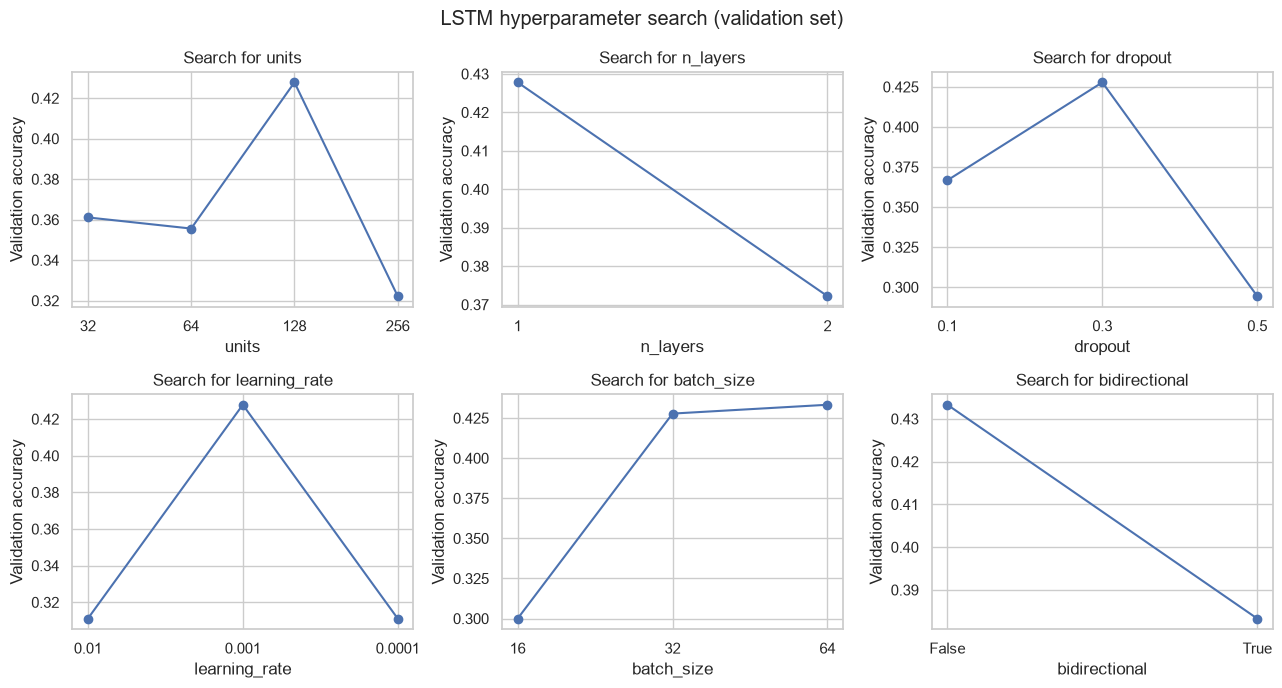

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, param in zip(axes.ravel(), search_space):
    sub = tuning_results[tuning_results.Parameter == param]
    ax.plot(sub.Value, sub.Val_accuracy, marker="o")
    ax.set_title(f"Search for {param}")
    ax.set_xlabel(param)
    ax.set_ylabel("Validation accuracy")
fig.suptitle("LSTM hyperparameter search (validation set)")
plt.tight_layout()
plt.savefig("output/lstm/figures/fig_lstm_tuning.png", dpi=300)
plt.show()

### 3.5 Effect of feature selection

In [ ]:
train_means = np.stack([X_train[i, :len_train[i]].mean(axis=0) for i in range(len(X_train))])
F, _ = f_classif(train_means, y_train)
ranking = np.argsort(F)[::-1]

feature_ranking = pd.DataFrame({"Rank": np.arange(1, 41),
                                "Attribute": [f"MFCC{i+1}" for i in ranking],
                                "ANOVA_F (train)": F[ranking].round(4)})
feature_ranking.to_csv("output/lstm/tables/table_lstm_feature_ranking.csv", index=False)
feature_ranking.head(10)

,Rank,Attribute,ANOVA_F (train)
0,1,MFCC3,35.4517
1,2,MFCC2,30.6607
2,3,MFCC5,21.7271
3,4,MFCC8,17.1821
4,5,MFCC21,15.1699
5,6,MFCC4,14.9113
6,7,MFCC6,13.8230
7,8,MFCC20,12.4097
8,9,MFCC39,12.1793
9,10,MFCC23,11.8757


In [ ]:
X_cv = np.concatenate([X_train, X_val])
y_cv = np.concatenate([y_train, y_val])
groups = np.concatenate([actors_train, actors_val])

rows = []
for k in [40, 20, 10, 5, 2, 1]:
    cols = np.sort(ranking[:k])
    accs, f1s = [], []
    for train_idx, test_idx in GroupKFold(n_splits=5).split(X_cv, y_cv, groups):
        X_tr, X_te = X_cv[train_idx][:, :, cols], X_cv[test_idx][:, :, cols]
        model, _ = train_lstm(best_params, X_tr, y_cv[train_idx], X_te, y_cv[test_idx])
        scores, _ = evaluate(model, X_te, y_cv[test_idx])
        accs.append(scores["Accuracy"])
        f1s.append(scores["F1-score"])
    rows.append({"Features": "All (40)" if k == 40 else f"Best {k}", "n_features": k,
                 "MFCCs used": " ".join(f"MFCC{i+1}" for i in ranking[:k]),
                 "CV_accuracy_mean": np.mean(accs), "CV_accuracy_std": np.std(accs),
                 "CV_F1_mean": np.mean(f1s)})
    print(f"{k} MFCCs: CV accuracy = {np.mean(accs):.4f} +/- {np.std(accs):.4f}")

subset_results = pd.DataFrame(rows).round(4)
subset_results.to_csv("output/lstm/tables/table_lstm_feature_subsets.csv", index=False)
best_k = int(subset_results.loc[subset_results.CV_accuracy_mean.idxmax(), "n_features"])
print("Best number of MFCCs:", best_k)
subset_results.drop(columns="MFCCs used")

40 MFCCs: CV accuracy = 0.3600 +/- 0.0534
20 MFCCs: CV accuracy = 0.3711 +/- 0.0656
10 MFCCs: CV accuracy = 0.4375 +/- 0.0545
5 MFCCs: CV accuracy = 0.4267 +/- 0.0621
2 MFCCs: CV accuracy = 0.3639 +/- 0.0466
1 MFCCs: CV accuracy = 0.2636 +/- 0.0354
Best number of MFCCs: 10


,Features,n_features,CV_accuracy_mean,CV_accuracy_std,CV_F1_mean
0,All (40),40,0.3600,0.0534,0.3401
1,Best 20,20,0.3711,0.0656,0.3564
2,Best 10,10,0.4375,0.0545,0.4113
3,Best 5,5,0.4267,0.0621,0.3986
4,Best 2,2,0.3639,0.0466,0.3458
5,Best 1,1,0.2636,0.0354,0.2186


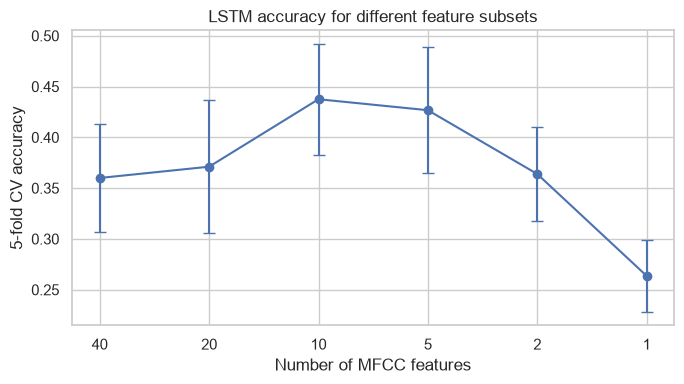

In [ ]:
plt.figure(figsize=(7, 4))
plt.errorbar(subset_results.n_features.astype(str), subset_results.CV_accuracy_mean,
             yerr=subset_results.CV_accuracy_std, marker="o", capsize=4)
plt.xlabel("Number of MFCC features")
plt.ylabel("5-fold CV accuracy")
plt.title("LSTM accuracy for different feature subsets")
plt.tight_layout()
plt.savefig("output/lstm/figures/fig_lstm_feature_subsets.png", dpi=300)
plt.show()

### 3.6 Final LSTM model (test set)

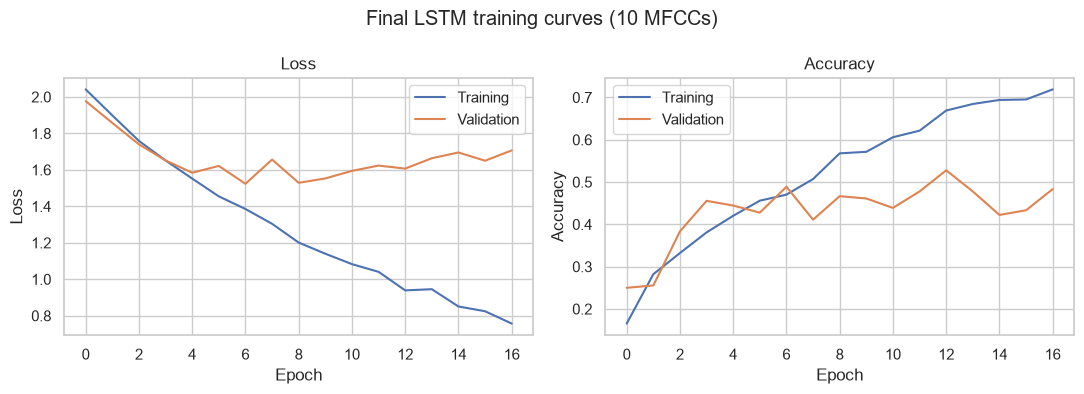

,Model,n_features,Accuracy,Precision,Recall,F1-score
0,LSTM,10,0.3929,0.3853,0.3929,0.378


In [ ]:
best_cols = np.sort(ranking[:best_k])
X_train_k, X_val_k, X_test_k = X_train[:, :, best_cols], X_val[:, :, best_cols], X_test[:, :, best_cols]

final_model, history = train_lstm(best_params, X_train_k, y_train, X_val_k, y_val)
final_model.save("output/lstm/models/lstm_final.keras")
plot_history(history, f"Final LSTM training curves ({best_k} MFCCs)", "fig_lstm_final_curves.png")

scores, y_pred = evaluate(final_model, X_test_k, y_test)
final_results = pd.DataFrame([{"Model": "LSTM", "n_features": best_k, **scores}]).round(4)
final_results.to_csv("output/lstm/tables/table_lstm_final_results.csv", index=False)
final_results

,precision,recall,f1-score,support
neutral,0.3793,0.3929,0.3860,28.0000
calm,0.5263,0.7143,0.6061,56.0000
happy,0.3167,0.3393,0.3276,56.0000
sad,0.3514,0.2321,0.2796,56.0000
angry,0.4062,0.4643,0.4333,56.0000
fearful,0.3731,0.4464,0.4065,56.0000
disgust,0.3485,0.4107,0.3770,56.0000
surprised,0.3810,0.1429,0.2078,56.0000
accuracy,0.3929,0.3929,0.3929,0.3929
macro avg,0.3853,0.3929,0.3780,420.0000


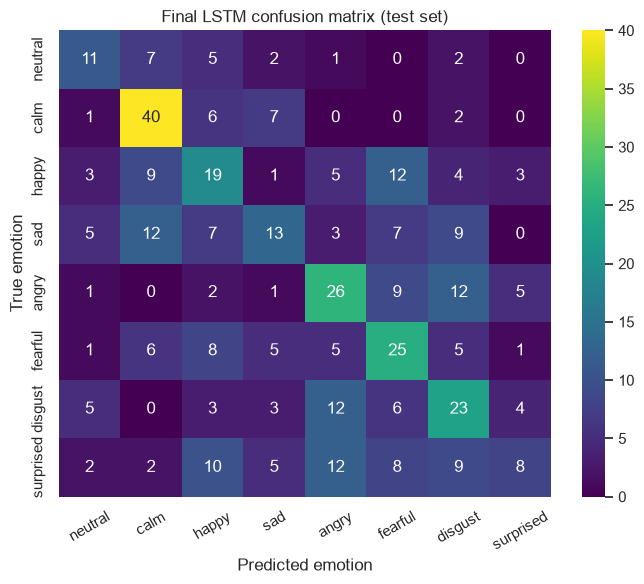

In [ ]:
report = pd.DataFrame(classification_report(y_test, y_pred, target_names=emotions,
                                           output_dict=True, zero_division=0)).T.round(4)
report.to_csv("output/lstm/tables/table_lstm_per_class_report.csv")
display(report)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="viridis", xticklabels=emotions, yticklabels=emotions)
plt.xlabel("Predicted emotion")
plt.ylabel("True emotion")
plt.title("Final LSTM confusion matrix (test set)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("output/lstm/figures/fig_lstm_confusion_matrix.png", dpi=300)
plt.show()

## 4. Transformer Model

In [ ]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

os.makedirs("output/transformer/tables", exist_ok=True)
os.makedirs("output/transformer/figures", exist_ok=True)
os.makedirs("output/transformer/models", exist_ok=True)

emotions = [
    "neutral", "calm", "happy", "sad",
    "angry", "fearful", "disgust", "surprised"
]

train = np.load("output/features/train.npz")
val = np.load("output/features/val.npz")

X_train, y_train = train["X"], train["y"]
len_train, actors_train = train["lengths"], train["actors"]

X_val, y_val = val["X"], val["y"]
len_val, actors_val = val["lengths"], val["actors"]

test_path = "output/features/test.npz"

if os.path.exists(test_path):
    test = np.load(test_path)
    X_test, y_test = test["X"], test["y"]
    len_test, actors_test = test["lengths"], test["actors"]
else:
    X_test = y_test = len_test = actors_test = None

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

if X_test is not None:
    print("Testing:", X_test.shape)
else:
    print("Test split unavailable: dataset preparation needs correction.")

Training: (840, 161, 40)
Validation: (180, 161, 40)
Testing: (420, 161, 40)


### 4.1 Transformer Architecture Definitions
Below we define custom layers for handling the sequence length mask (`KeyMask` and `MaskedAverage`) to ensure padded elements do not skew calculations. We then construct a standard Multi-Head Attention architecture designed to capture global dependencies across the extracted MFCC frame sequence.

### 4.1 Transformer Architecture Definitions
Below we define custom layers for handling the sequence length mask (`KeyMask` and `MaskedAverage`) to ensure padded elements do not skew calculations. We then construct a standard Multi-Head Attention architecture designed to capture global dependencies across the extracted MFCC frame sequence.

In [ ]:
class KeyMask(layers.Layer):
    def call(self, inputs):
        x, lengths = inputs
        mask = tf.sequence_mask(
            lengths,
            maxlen=tf.shape(x)[1]
        )
        return mask[:, tf.newaxis, :]


class MaskedAverage(layers.Layer):
    def call(self, inputs):
        x, lengths = inputs

        mask = tf.sequence_mask(
            lengths,
            maxlen=tf.shape(x)[1],
            dtype=x.dtype
        )

        mask = mask[:, :, tf.newaxis]

        return tf.reduce_sum(x * mask, axis=1) / tf.maximum(
            tf.reduce_sum(mask, axis=1), 1.0
        )


def build_transformer(
    n_steps,
    n_features,
    d_model=128,
    num_heads=4,
    ff_dim=256,
    n_layers=2,
    dropout=0.2
):

    mfcc = keras.Input(
        shape=(n_steps, n_features),
        name="mfcc"
    )

    lengths = keras.Input(
        shape=(),
        dtype="int32",
        name="lengths"
    )

    x = layers.Dense(d_model)(mfcc)

    positions = tf.range(n_steps)

    position_embedding = layers.Embedding(
        n_steps,
        d_model
    )(positions)

    x = x + position_embedding

    attention_mask = KeyMask()([mfcc, lengths])

    for _ in range(n_layers):

        attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=d_model // num_heads,
            dropout=dropout
        )(
            x, x,
            attention_mask=attention_mask
        )

        x = layers.LayerNormalization()(
            x + layers.Dropout(dropout)(attention)
        )

        ff = layers.Dense(
            ff_dim,
            activation="relu"
        )(x)

        ff = layers.Dense(d_model)(ff)

        x = layers.LayerNormalization()(
            x + layers.Dropout(dropout)(ff)
        )

    x = MaskedAverage()([x, lengths])

    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(dropout)(x)

    outputs = layers.Dense(
        8,
        activation="softmax"
    )(x)

    return keras.Model(
        inputs=[mfcc, lengths],
        outputs=outputs
    )

In [ ]:
def get_class_weights(y):
    counts = np.bincount(y, minlength=8)
    return {
        i: len(y) / (8 * counts[i])
        for i in range(8) if counts[i] > 0
    }


def train_transformer(params, X_tr, y_tr, L_tr, X_va, y_va, L_va):

    tf.keras.utils.set_random_seed(42)

    model = build_transformer(
        X_tr.shape[1],
        X_tr.shape[2],
        params["d_model"],
        params["num_heads"],
        params["ff_dim"],
        params["n_layers"],
        params["dropout"]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=params["learning_rate"]
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        [X_tr, L_tr],
        y_tr,
        validation_data=([X_va, L_va], y_va),
        epochs=100,
        batch_size=params["batch_size"],
        class_weight=get_class_weights(y_tr),
        callbacks=[early_stop],
        verbose=0
    )

    return model, history.history


def evaluate_transformer(model, X, y, lengths):

    predictions = model.predict(
        [X, lengths],
        verbose=0
    ).argmax(axis=1)

    scores = {
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(
            y, predictions, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y, predictions, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y, predictions, average="macro", zero_division=0
        )
    }

    return scores, predictions


def plot_history(history, title, filename):

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(history["loss"], label="Training")
    axes[0].plot(history["val_loss"], label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history["accuracy"], label="Training")
    axes[1].plot(history["val_accuracy"], label="Validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()

    plt.savefig(
        f"output/transformer/figures/{filename}",
        dpi=300
    )

    plt.show()

Model: "functional_49"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ mfcc (InputLayer)   │ (None, 161, 40)   │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_98 (Dense)    │ (None, 161, 128)  │      5,248 │ mfcc[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lengths             │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 161, 128)  │          0 │ dense_98[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ key_mask (KeyMask)  │ (None, 1, 161)    │          0 │ mfcc[0][0],       │
│                     │                   │            │ lengths[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 161, 128)  │     66,048 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0],        │
│                     │                   │            │ key_mask[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_100         │ (None, 161, 128)  │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 161, 128)  │          0 │ add[0][0],        │
│                     │                   │            │ dropout_100[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 161, 128)  │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_99 (Dense)    │ (None, 161, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_100 (Dense)   │ (None, 161, 128)  │     32,896 │ dense_99[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_101         │ (None, 161, 128)  │          0 │ dense_100[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 161, 128)  │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_101[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 161, 128)  │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 161, 128)  │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
│                     │                   │            │ key_mask[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_103         │ (None, 161, 128)  │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 161, 128)  │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_103[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 161, 128)  │        256 │ add_3[0][0]     

 Total params: 836,954 (3.19 MB)

 Trainable params: 278,984 (1.06 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 557,970 (2.13 MB)

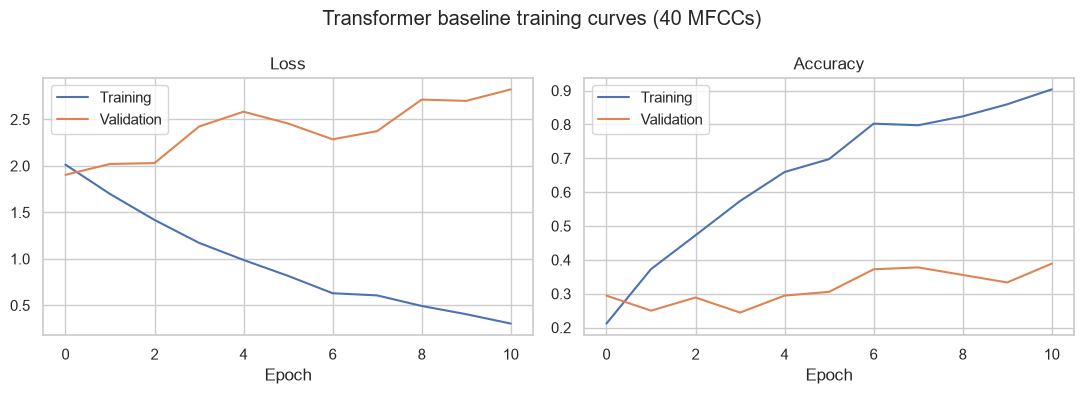

In [ ]:
default_params = {
    "d_model": 128,
    "num_heads": 4,
    "ff_dim": 256,
    "n_layers": 2,
    "dropout": 0.2,
    "learning_rate": 0.001,
    "batch_size": 32
}

baseline_model, baseline_history = train_transformer(
    default_params,
    X_train, y_train, len_train,
    X_val, y_val, len_val
)

baseline_model.summary()

plot_history(
    baseline_history,
    "Transformer baseline training curves (40 MFCCs)",
    "fig_transformer_baseline.png"
)

baseline_results = []

for name, X, y, lengths in [
    ("Train", X_train, y_train, len_train),
    ("Validation", X_val, y_val, len_val)
]:

    scores, _ = evaluate_transformer(
        baseline_model, X, y, lengths
    )

    baseline_results.append({
        "Set": name,
        **scores
    })

pd.DataFrame(baseline_results).round(4).to_csv(
    "output/transformer/tables/table_transformer_baseline.csv",
    index=False
)

### 4.2 Baseline Transformer Training
With our architecture defined, we train a baseline Transformer model using our default parameters (such as `d_model=128`, `num_heads=4`, etc.) on all 40 raw MFCC features. This gives us a benchmark performance against which we can evaluate our upcoming optimization steps.

In [ ]:
search_space = {
    "d_model": [32, 64, 128, 256],
    "num_heads": [2, 4, 8],
    "ff_dim": [128, 256, 512],
    "n_layers": [1, 2, 3],
    "dropout": [0.1, 0.2, 0.3, 0.5],
    "learning_rate": [0.01, 0.001, 0.0001],
    "batch_size": [16, 32, 64]
}

best_params = dict(default_params)
tuning_rows = []

for param, values in search_space.items():

    val_accs = []

    for value in values:

        params = dict(best_params)
        params[param] = value

        if params["d_model"] % params["num_heads"] != 0:
            continue

        model, history = train_transformer(
            params,
            X_train, y_train, len_train,
            X_val, y_val, len_val
        )

        scores, _ = evaluate_transformer(
            model, X_val, y_val, len_val
        )

        val_accs.append(scores["Accuracy"])

        tuning_rows.append({
            "Parameter": param,
            "Value": value,
            "Validation Accuracy": scores["Accuracy"],
            "Validation F1": scores["F1-score"],
            "Epochs": len(history["loss"])
        })

        print(
            f"{param} = {value}: "
            f"Validation accuracy = {scores['Accuracy']:.4f}"
        )

        del model
        gc.collect()

    if val_accs:
        valid_values = [
            v for v in values
            if param != "num_heads"
            or best_params["d_model"] % v == 0
        ]

        best_params[param] = valid_values[np.argmax(val_accs)]

    print(f"Best {param}: {best_params[param]}")

tuning_results = pd.DataFrame(tuning_rows)

tuning_results.to_csv(
    "output/transformer/tables/table_transformer_tuning.csv",
    index=False
)

pd.DataFrame({
    "Parameter": list(best_params.keys()),
    "Optimal value": list(best_params.values())
}).to_csv(
    "output/transformer/tables/table_transformer_optimal_params.csv",
    index=False
)

display(tuning_results)
print("Optimal parameters:", best_params)

d_model = 32: Validation accuracy = 0.2611
d_model = 64: Validation accuracy = 0.2722
d_model = 128: Validation accuracy = 0.2944
d_model = 256: Validation accuracy = 0.2056
Best d_model: 128
num_heads = 2: Validation accuracy = 0.2389
num_heads = 4: Validation accuracy = 0.2944
num_heads = 8: Validation accuracy = 0.3000
Best num_heads: 8
ff_dim = 128: Validation accuracy = 0.3389
ff_dim = 256: Validation accuracy = 0.3000
ff_dim = 512: Validation accuracy = 0.2778
Best ff_dim: 128
n_layers = 1: Validation accuracy = 0.3000
n_layers = 2: Validation accuracy = 0.3389
n_layers = 3: Validation accuracy = 0.2833
Best n_layers: 2
dropout = 0.1: Validation accuracy = 0.2833
dropout = 0.2: Validation accuracy = 0.3389
dropout = 0.3: Validation accuracy = 0.3222
dropout = 0.5: Validation accuracy = 0.2222
Best dropout: 0.2
learning_rate = 0.01: Validation accuracy = 0.1333
learning_rate = 0.001: Validation accuracy = 0.3389
learning_rate = 0.0001: Validation accuracy = 0.3056
Best learning_ra

,Parameter,Value,Validation Accuracy,Validation F1,Epochs
0,d_model,32.0000,0.261111,0.233454,13
1,d_model,64.0000,0.272222,0.245338,12
2,d_model,128.0000,0.294444,0.246008,11
3,d_model,256.0000,0.205556,0.181339,11
4,num_heads,2.0000,0.238889,0.211916,11
5,num_heads,4.0000,0.294444,0.246008,11
6,num_heads,8.0000,0.300000,0.251359,13
7,ff_dim,128.0000,0.338889,0.308374,13
8,ff_dim,256.0000,0.300000,0.251359,13
9,ff_dim,512.0000,0.277778,0.232855,11


Optimal parameters: {'d_model': 128, 'num_heads': 8, 'ff_dim': 128, 'n_layers': 2, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 32}


### 4.3 Hyperparameter Optimization via Grid Search
To squeeze out extra performance, we sweep across a defined grid of values including the dimensionality of model embeddings (`d_model`), attention heads (`num_heads`), dropout rates, and learning rates. This systematic approach identifies the most effective configuration for our RAVDESS speaker split.

In [ ]:
from sklearn.model_selection import GroupKFold

ranking_df = pd.read_csv(
    "output/lstm/tables/table_lstm_feature_ranking.csv"
)

ranking = np.array([
    int(x.replace("MFCC", "")) - 1
    for x in ranking_df["Attribute"]
])

X_cv = np.concatenate([X_train, X_val])
y_cv = np.concatenate([y_train, y_val])
L_cv = np.concatenate([len_train, len_val])

groups = np.concatenate([actors_train, actors_val])

feature_rows = []

for k in [40, 20, 10, 5, 2, 1]:

    cols = np.sort(ranking[:k])

    accs, f1s = [], []

    for train_idx, val_idx in GroupKFold(n_splits=5).split(
        X_cv, y_cv, groups
    ):

        model, history = train_transformer(
            best_params,
            X_cv[train_idx][:, :, cols],
            y_cv[train_idx],
            L_cv[train_idx],
            X_cv[val_idx][:, :, cols],
            y_cv[val_idx],
            L_cv[val_idx]
        )

        scores, _ = evaluate_transformer(
            model,
            X_cv[val_idx][:, :, cols],
            y_cv[val_idx],
            L_cv[val_idx]
        )

        accs.append(scores["Accuracy"])
        f1s.append(scores["F1-score"])

        del model
        gc.collect()

    feature_rows.append({
        "Features": f"Best {k}" if k != 40 else "All (40)",
        "n_features": k,
        "MFCCs": ", ".join(f"MFCC{i+1}" for i in ranking[:k]),
        "CV_accuracy_mean": np.mean(accs),
        "CV_accuracy_std": np.std(accs),
        "CV_F1_mean": np.mean(f1s)
    })

    print(
        f"{k} features: "
        f"CV accuracy = {np.mean(accs):.4f} "
        f"+/- {np.std(accs):.4f}"
    )

feature_results = pd.DataFrame(feature_rows)

feature_results.to_csv(
    "output/transformer/tables/table_transformer_feature_selection.csv",
    index=False
)

display(feature_results)

best_k = int(
    feature_results.loc[
        feature_results["CV_accuracy_mean"].idxmax(),
        "n_features"
    ]
)

print("Best number of features:", best_k)

40 features: CV accuracy = 0.3350 +/- 0.0852
20 features: CV accuracy = 0.4000 +/- 0.0845
10 features: CV accuracy = 0.3492 +/- 0.0539
5 features: CV accuracy = 0.3394 +/- 0.0191
2 features: CV accuracy = 0.2889 +/- 0.0407
1 features: CV accuracy = 0.2125 +/- 0.0144


,Features,n_features,MFCCs,CV_accuracy_mean,CV_accuracy_std,CV_F1_mean
0,All (40),40,"MFCC3, MFCC2, MFCC5, MFCC8, MFCC21, MFCC4, MFC...",0.335000,0.085230,0.320246
1,Best 20,20,"MFCC3, MFCC2, MFCC5, MFCC8, MFCC21, MFCC4, MFC...",0.400000,0.084547,0.384569
2,Best 10,10,"MFCC3, MFCC2, MFCC5, MFCC8, MFCC21, MFCC4, MFC...",0.349167,0.053932,0.327402
3,Best 5,5,"MFCC3, MFCC2, MFCC5, MFCC8, MFCC21",0.339444,0.019116,0.327501
4,Best 2,2,"MFCC3, MFCC2",0.288889,0.040711,0.271150
5,Best 1,1,MFCC3,0.212500,0.014380,0.160106


Best number of features: 20


### 4.4 Feature Selection & Dimensionality Analysis
Using Group K-Fold Cross-Validation, we evaluate how reducing the number of input features impacts Transformer performance. Selecting a streamlined subset of MFCCs can significantly improve model generalization, reduce computation times, and mitigate overfitting.

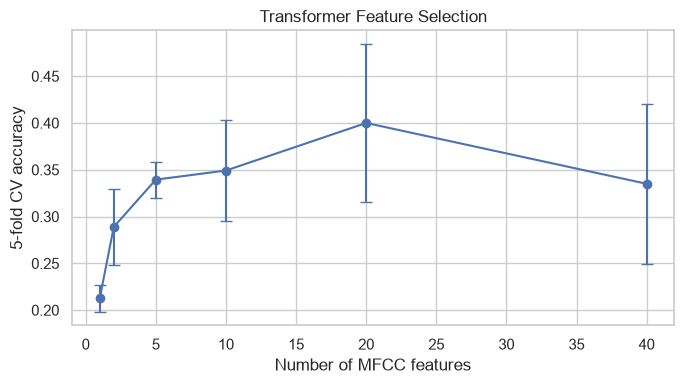

In [ ]:
plt.figure(figsize=(7, 4))

plt.errorbar(
    feature_results["n_features"],
    feature_results["CV_accuracy_mean"],
    yerr=feature_results["CV_accuracy_std"],
    marker="o",
    capsize=4
)

plt.xlabel("Number of MFCC features")
plt.ylabel("5-fold CV accuracy")
plt.title("Transformer Feature Selection")

plt.tight_layout()

plt.savefig(
    "output/transformer/figures/fig_transformer_feature_selection.png",
    dpi=300
)

plt.show()

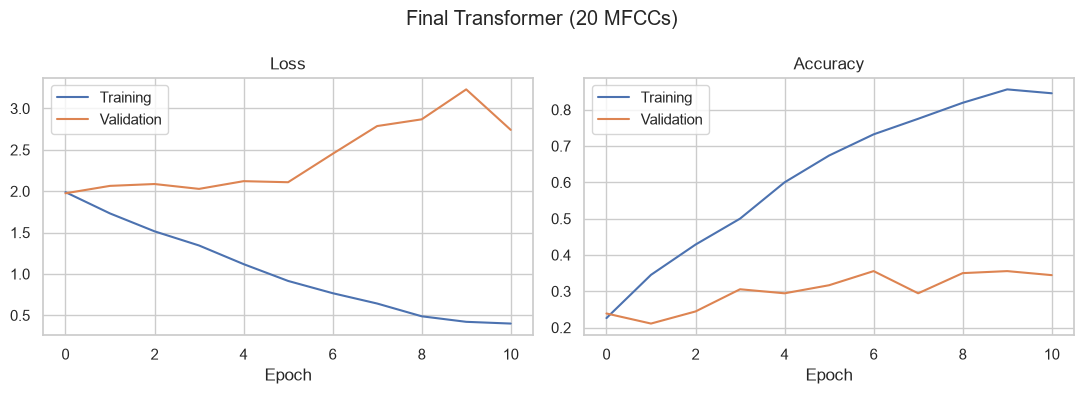

In [ ]:
best_cols = np.sort(ranking[:best_k])

X_train_final = X_train[:, :, best_cols]
X_val_final = X_val[:, :, best_cols]

final_model, final_history = train_transformer(
    best_params,
    X_train_final,
    y_train,
    len_train,
    X_val_final,
    y_val,
    len_val
)

final_model.save(
    "output/transformer/models/transformer_final.keras"
)

plot_history(
    final_history,
    f"Final Transformer ({best_k} MFCCs)",
    "fig_transformer_final.png"
)

In [ ]:
if X_test is not None and len(X_test) > 0:

    X_test_final = X_test[:, :, best_cols]

    scores, y_pred = evaluate_transformer(
        final_model,
        X_test_final,
        y_test,
        len_test
    )

    final_results = pd.DataFrame([{
        "Model": "Transformer",
        "n_features": best_k,
        **scores
    }])

    final_results.to_csv(
        "output/transformer/tables/table_transformer_final_results.csv",
        index=False
    )

    display(final_results)

else:
    print("Final test evaluation unavailable: test split is empty.")

,Model,n_features,Accuracy,Precision,Recall,F1-score
0,Transformer,20,0.264286,0.353281,0.274554,0.245336


In [ ]:
if X_test is not None and len(X_test) > 0:

    X_test_final = X_test[:, :, best_cols]

    scores, y_pred = evaluate_transformer(
        final_model,
        X_test_final,
        y_test,
        len_test
    )

    final_results = pd.DataFrame([{
        "Model": "Transformer",
        "n_features": best_k,
        **scores
    }])

    final_results.to_csv(
        "output/transformer/tables/table_transformer_final_results.csv",
        index=False
    )

    display(final_results)

else:
    print("Final test evaluation unavailable: test split is empty.")

,Model,n_features,Accuracy,Precision,Recall,F1-score
0,Transformer,20,0.264286,0.353281,0.274554,0.245336


,precision,recall,f1-score,support
neutral,0.1818,0.4286,0.2553,28.0000
calm,0.7143,0.0893,0.1587,56.0000
happy,0.2183,0.5536,0.3131,56.0000
sad,0.2391,0.1964,0.2157,56.0000
angry,0.4167,0.0893,0.1471,56.0000
fearful,0.4167,0.2679,0.3261,56.0000
disgust,0.2644,0.4107,0.3217,56.0000
surprised,0.3750,0.1607,0.2250,56.0000
accuracy,0.2643,0.2643,0.2643,0.2643
macro avg,0.3533,0.2746,0.2453,420.0000


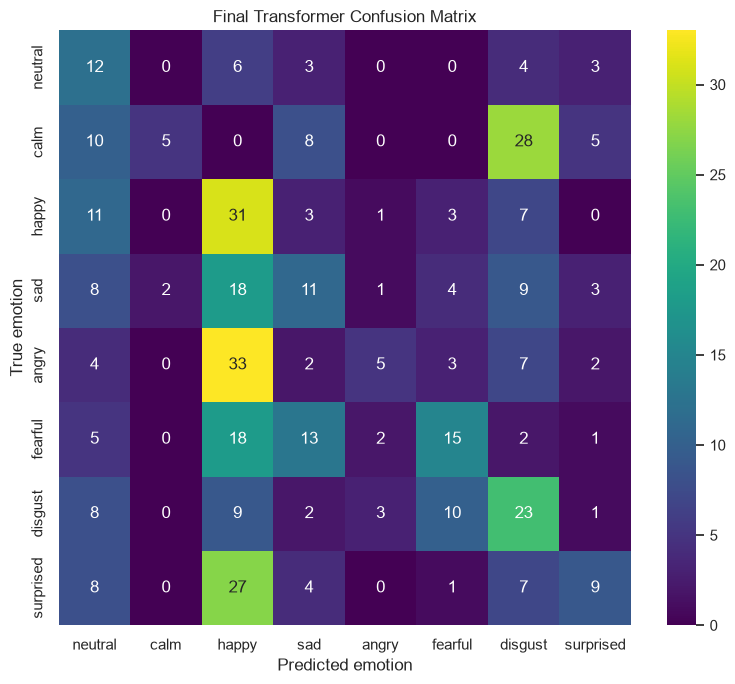

In [ ]:
if X_test is not None and len(X_test) > 0:

    report = pd.DataFrame(
        classification_report(
            y_test,
            y_pred,
            target_names=emotions,
            output_dict=True,
            zero_division=0
        )
    ).T.round(4)

    report.to_csv(
        "output/transformer/tables/table_transformer_classification_report.csv"
    )

    display(report)

    cm = confusion_matrix(y_test, y_pred)

    fig, ax = plt.subplots(figsize=(8, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="viridis",
        xticklabels=emotions,
        yticklabels=emotions,
        ax=ax
    )

    ax.set_xlabel("Predicted emotion")
    ax.set_ylabel("True emotion")
    ax.set_title("Final Transformer Confusion Matrix")

    plt.tight_layout()

    plt.savefig(
        "output/transformer/figures/fig_transformer_confusion_matrix.png",
        dpi=300
    )

    plt.show()


## 5.2 Experimental Setup

### Experimental Workflow

The workflow illustrates the main stages of the speech emotion recognition experiment, from audio preprocessing and MFCC extraction to model training, optimization, and final evaluation.


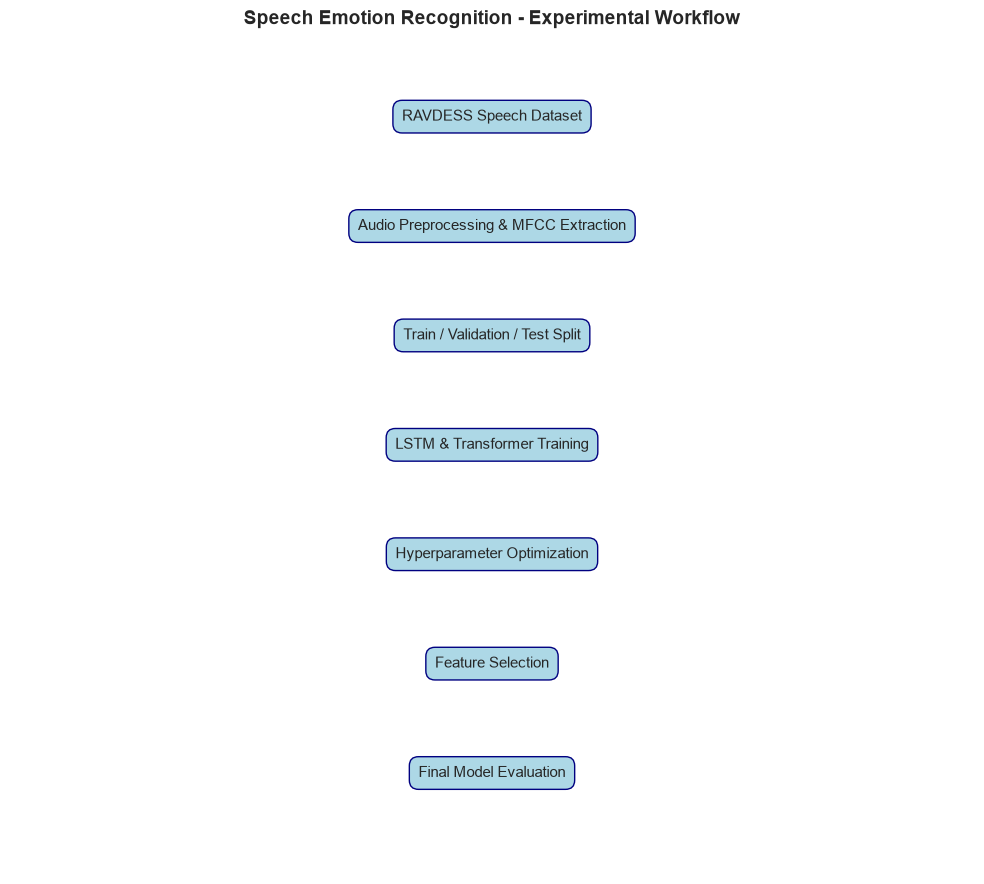

In [ ]:

# Experimental Workflow

import matplotlib.pyplot as plt

steps = [
    "RAVDESS Speech Dataset",
    "Audio Preprocessing & MFCC Extraction",
    "Train / Validation / Test Split",
    "LSTM & Transformer Training",
    "Hyperparameter Optimization",
    "Feature Selection",
    "Final Model Evaluation"
]

fig, ax = plt.subplots(figsize=(10, 9))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

for i, step in enumerate(steps):
    y = 9 - i * 1.3

    ax.text(
        5, y, step,
        ha="center", va="center", fontsize=11,
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="lightblue",
            edgecolor="navy"
        )
    )

    if i < len(steps) - 1:
        ax.annotate(
            "",
            xy=(5, y - 1.05),
            xytext=(5, y - 0.3),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

ax.set_title(
    "Speech Emotion Recognition - Experimental Workflow",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "fig_experimental_workflow.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


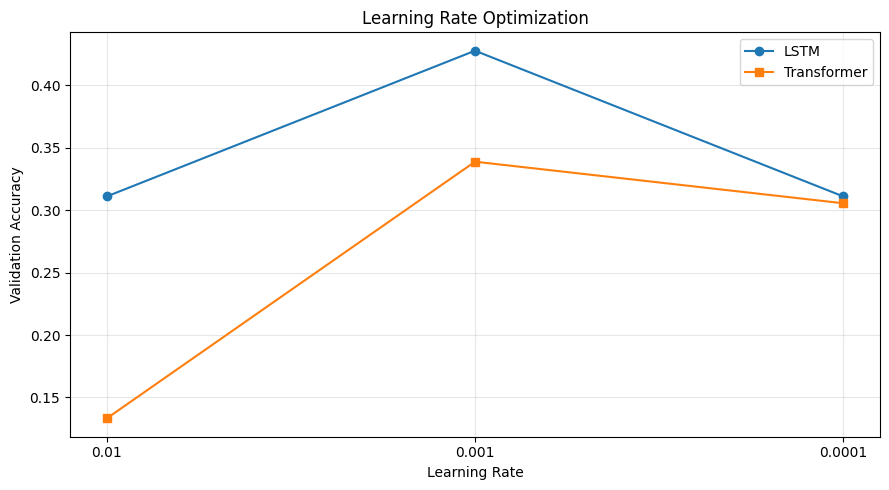

In [1]:

# Hyperparameter Optimization - Learning Rate

import matplotlib.pyplot as plt

learning_rates = ["0.01", "0.001", "0.0001"]

lstm_accuracy = [0.3111, 0.4278, 0.3111]
transformer_accuracy = [0.1333, 0.3389, 0.3056]

plt.figure(figsize=(9, 5))

plt.plot(
    learning_rates,
    lstm_accuracy,
    marker="o",
    label="LSTM"
)

plt.plot(
    learning_rates,
    transformer_accuracy,
    marker="s",
    label="Transformer"
)

plt.title("Learning Rate Optimization")
plt.xlabel("Learning Rate")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "fig_learning_rate_optimization.png",
    dpi=300
)
plt.show()



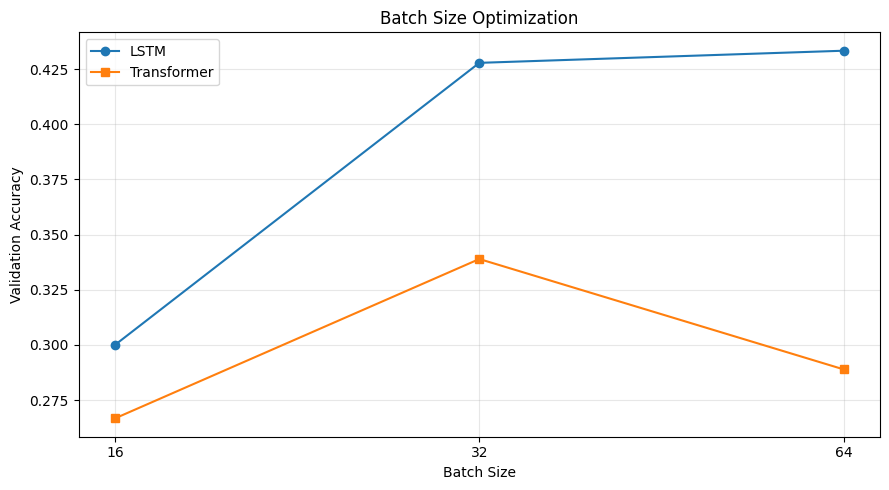

In [2]:

# Hyperparameter Optimization - Batch Size

import matplotlib.pyplot as plt

batch_sizes = ["16", "32", "64"]

lstm_accuracy = [0.3000, 0.4278, 0.4333]
transformer_accuracy = [0.2667, 0.3389, 0.2889]

plt.figure(figsize=(9, 5))

plt.plot(
    batch_sizes,
    lstm_accuracy,
    marker="o",
    label="LSTM"
)

plt.plot(
    batch_sizes,
    transformer_accuracy,
    marker="s",
    label="Transformer"
)

plt.title("Batch Size Optimization")
plt.xlabel("Batch Size")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "fig_batch_size_optimization.png",
    dpi=300
)
plt.show()


In [3]:

# Optimal Hyperparameters

import pandas as pd
from IPython.display import display

optimal_params = pd.DataFrame([
    ["LSTM", "Units", 128],
    ["LSTM", "Number of Layers", 1],
    ["LSTM", "Dropout", 0.3],
    ["LSTM", "Learning Rate", 0.001],
    ["LSTM", "Batch Size", 64],
    ["LSTM", "Bidirectional", False],
    ["Transformer", "Model Dimension", 128],
    ["Transformer", "Attention Heads", 8],
    ["Transformer", "Feed-Forward Dimension", 128],
    ["Transformer", "Number of Layers", 2],
    ["Transformer", "Dropout", 0.2],
    ["Transformer", "Learning Rate", 0.001],
    ["Transformer", "Batch Size", 32]
], columns=[
    "Model",
    "Hyperparameter",
    "Optimal Value"
])

display(optimal_params)

optimal_params.to_csv(
    "optimal_hyperparameters.csv",
    index=False
)


,Model,Hyperparameter,Optimal Value
0,LSTM,Units,128
1,LSTM,Number of Layers,1
2,LSTM,Dropout,0.3
3,LSTM,Learning Rate,0.001
4,LSTM,Batch Size,64
5,LSTM,Bidirectional,False
6,Transformer,Model Dimension,128
7,Transformer,Attention Heads,8
8,Transformer,Feed-Forward Dimension,128
9,Transformer,Number of Layers,2


Loaded LSTM parameters: {'units': 128, 'n_layers': 1, 'dropout': 0.3, 'learning_rate': 0.001, 'batch_size': 64, 'bidirectional': False}
Loaded Transformer parameters: {'d_model': 128, 'num_heads': 8, 'ff_dim': 128, 'n_layers': 2, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 32}
LSTM | 40 features | Fold 1/5 | Accuracy: 0.3111 | Macro F1: 0.2719
LSTM | 40 features | Fold 2/5 | Accuracy: 0.2944 | Macro F1: 0.2739
LSTM | 40 features | Fold 3/5 | Accuracy: 0.3611 | Macro F1: 0.3463
LSTM | 40 features | Fold 4/5 | Accuracy: 0.2389 | Macro F1: 0.1859
LSTM | 40 features | Fold 5/5 | Accuracy: 0.3167 | Macro F1: 0.2856
LSTM | 40 features | Mean accuracy: 0.3044 | Mean Macro F1: 0.2727
LSTM | 20 features | Fold 1/5 | Accuracy: 0.3167 | Macro F1: 0.2812
LSTM | 20 features | Fold 2/5 | Accuracy: 0.2500 | Macro F1: 0.2186
LSTM | 20 features | Fold 3/5 | Accuracy: 0.4278 | Macro F1: 0.4185
LSTM | 20 features | Fold 4/5 | Accuracy: 0.3222 | Macro F1: 0.3148
LSTM | 20 features | Fold 5/5 | A

,Model,n_features,CV_accuracy_mean,CV_accuracy_std,CV_F1_mean
0,LSTM,1,0.2328,0.0443,0.1977
1,LSTM,2,0.2706,0.0127,0.2381
2,LSTM,5,0.3256,0.0577,0.3011
3,LSTM,10,0.3706,0.0814,0.3436
4,LSTM,20,0.3350,0.0650,0.3165
5,LSTM,40,0.3044,0.0442,0.2727
6,Transformer,1,0.1772,0.0531,0.1477
7,Transformer,2,0.2583,0.0375,0.2249
8,Transformer,5,0.2822,0.0433,0.2449
9,Transformer,10,0.2922,0.0472,0.2576


BEST FEATURE SUBSETS


,Model,Best_Number_of_Features,CV_Accuracy,CV_Accuracy_STD,CV_Macro_F1
0,LSTM,10,0.3706,0.0814,0.3436
1,Transformer,10,0.2922,0.0472,0.2576


LSTM VS TRANSFORMER FEATURE-SELECTION COMPARISON


,Number_of_Features,LSTM_Accuracy,LSTM_Accuracy_STD,LSTM_Macro_F1,Transformer_Accuracy,Transformer_Accuracy_STD,Transformer_Macro_F1
5,40,0.3044,0.0442,0.2727,0.2667,0.0269,0.2344
4,20,0.3350,0.0650,0.3165,0.2644,0.0262,0.2462
3,10,0.3706,0.0814,0.3436,0.2922,0.0472,0.2576
2,5,0.3256,0.0577,0.3011,0.2822,0.0433,0.2449
1,2,0.2706,0.0127,0.2381,0.2583,0.0375,0.2249
0,1,0.2328,0.0443,0.1977,0.1772,0.0531,0.1477


TOP 10 RANKED MFCC FEATURES


,Rank,Attribute,ANOVA_F (train),P_Value
0,1,MFCC3,35.451739,0.0
1,2,MFCC2,30.660729,0.0
2,3,MFCC5,21.727148,0.0
3,4,MFCC8,17.182121,0.0
4,5,MFCC21,15.169889,0.0
5,6,MFCC4,14.911304,0.0
6,7,MFCC6,13.823011,0.0
7,8,MFCC20,12.409749,0.0
8,9,MFCC39,12.179275,0.0
9,10,MFCC23,11.875739,0.0


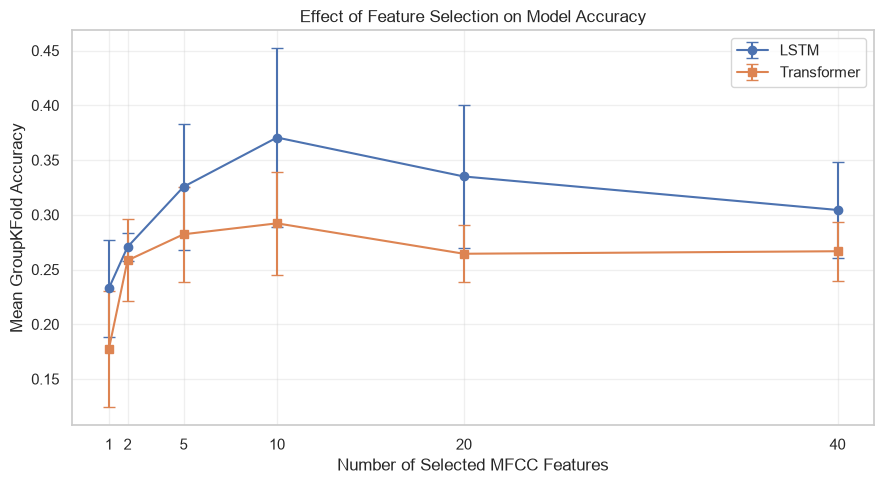

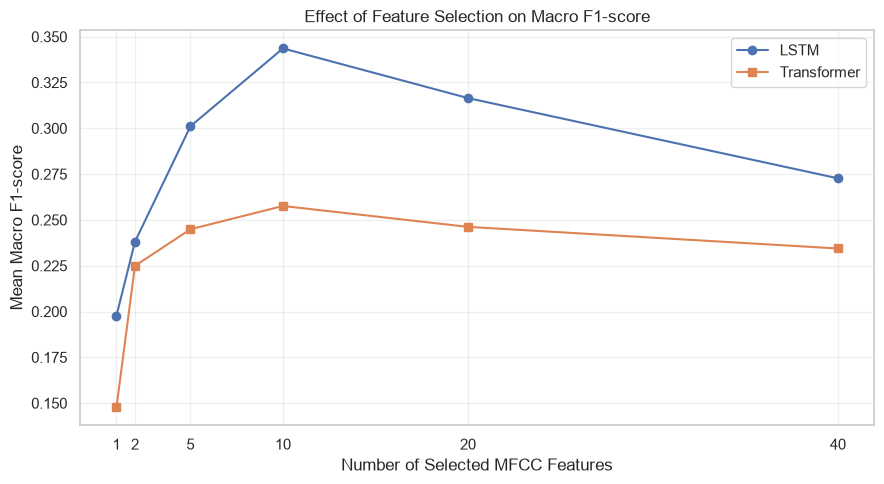

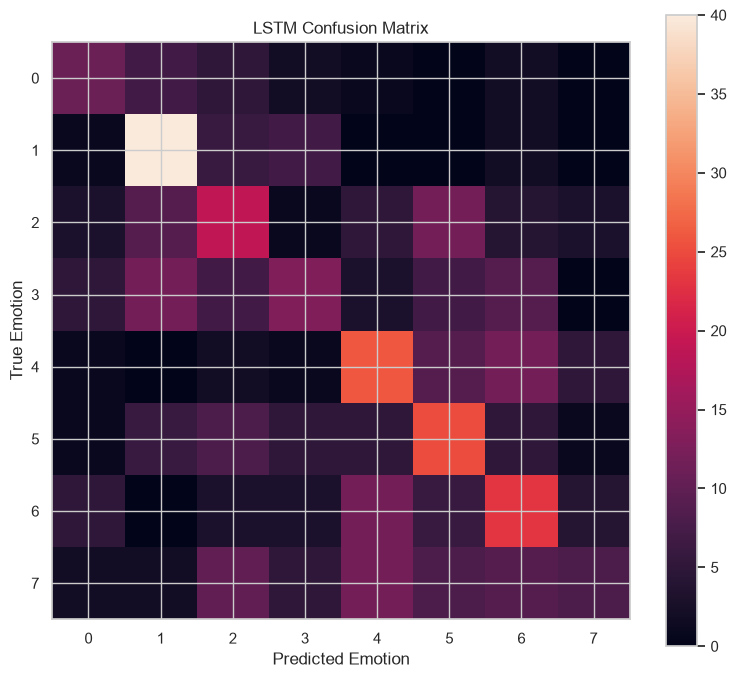

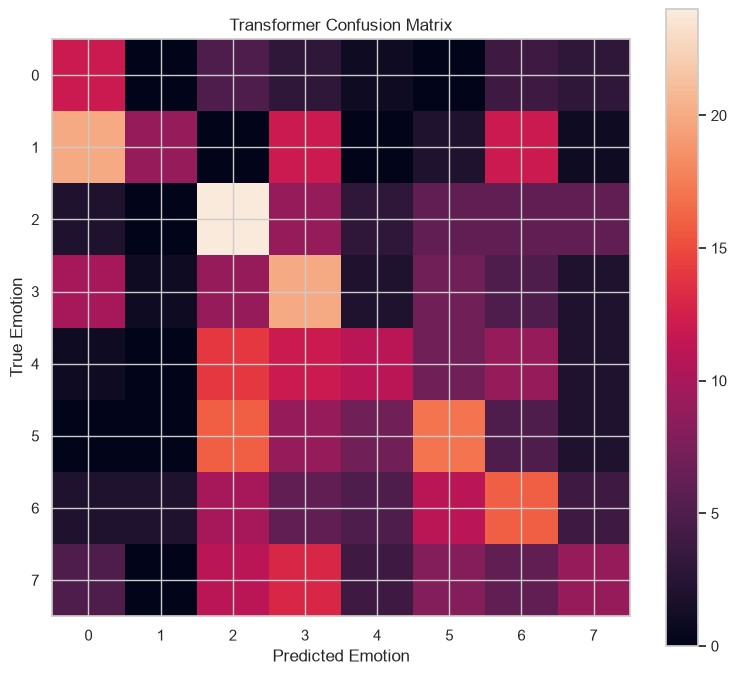

FINAL HELD-OUT TEST RESULTS


,Model,n_features,Accuracy,Precision,Recall,F1-score
0,LSTM,10,0.3929,0.3853,0.3929,0.3780
1,Transformer,10,0.2810,0.3349,0.2902,0.2759


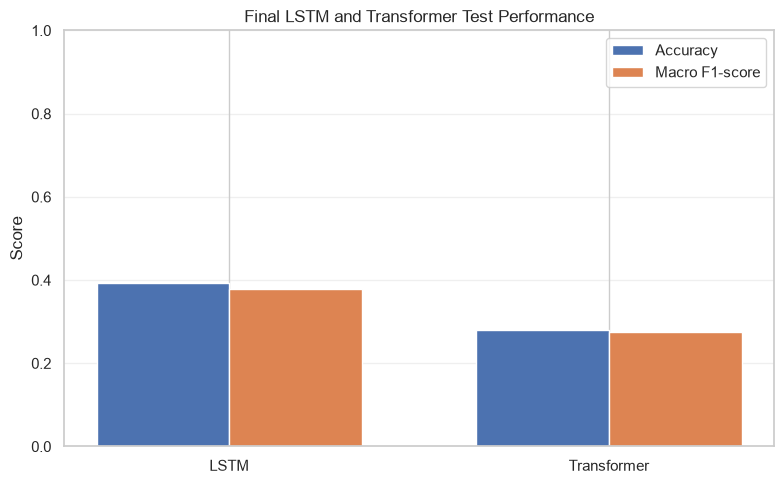


FEATURE SELECTION AND RESULTS ANALYSIS COMPLETED.
Generated files are saved in the output/results folder.


In [ ]:
# ============================================================
# FEATURE SELECTION AND RESULTS ANALYSIS
# LSTM vs Transformer
# Leakage-safe GroupKFold Cross-Validation
# ============================================================
#
# Run this cell AFTER:
# 1. Dataset preparation and train/validation/test splitting.
# 2. LSTM and Transformer model/function definitions.
# 3. LSTM and Transformer hyperparameter tuning.
#
# Required existing variables/functions:
# X_train, y_train, len_train, actors_train
# X_val, y_val, len_val
# X_test, y_test, len_test
# train_lstm, evaluate
# train_transformer, evaluate_transformer
#
# This code combines the feature-selection experiments and the
# result tables/plots in one place. It does not use a personal name
# in any variable, file, folder, title, or printed message.
# ============================================================

import os
import gc
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.feature_selection import f_classif
from sklearn.metrics import confusion_matrix
from IPython.display import display


# ------------------------------------------------------------
# 1. Create output folders
# ------------------------------------------------------------

os.makedirs("output/lstm/tables", exist_ok=True)
os.makedirs("output/transformer/tables", exist_ok=True)
os.makedirs("output/results", exist_ok=True)
os.makedirs("output/results/figures", exist_ok=True)
os.makedirs("output/results/models", exist_ok=True)


# ------------------------------------------------------------
# 2. Load the optimal hyperparameters
# ------------------------------------------------------------

def load_parameters(file_path, value_column):
    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"Parameter file not found: {file_path}. "
            "Run the corresponding hyperparameter-tuning cell first."
        )

    parameter_table = pd.read_csv(file_path)

    required_columns = {"Parameter", value_column}
    if not required_columns.issubset(parameter_table.columns):
        raise ValueError(
            f"{file_path} must contain these columns: "
            f"{sorted(required_columns)}. "
            f"Found: {parameter_table.columns.tolist()}"
        )

    parameters = {}

    for _, row in parameter_table.iterrows():
        value = row[value_column]

        # Convert values saved as strings (e.g. "True", "64", "0.001").
        try:
            value = ast.literal_eval(str(value))
        except (ValueError, SyntaxError):
            pass

        parameters[row["Parameter"]] = value

    return parameters


lstm_params = load_parameters(
    "output/lstm/tables/table_lstm_optimal_params.csv",
    "Optimal value chosen"
)

transformer_params = load_parameters(
    "output/transformer/tables/table_transformer_optimal_params.csv",
    "Optimal value"
)


# Convert model parameters to the required Python types.
for key in ["units", "n_layers", "batch_size"]:
    if key in lstm_params:
        lstm_params[key] = int(float(lstm_params[key]))

for key in ["d_model", "num_heads", "ff_dim", "n_layers", "batch_size"]:
    if key in transformer_params:
        transformer_params[key] = int(float(transformer_params[key]))

for key in ["dropout", "learning_rate"]:
    if key in lstm_params:
        lstm_params[key] = float(lstm_params[key])

    if key in transformer_params:
        transformer_params[key] = float(transformer_params[key])

if transformer_params["d_model"] % transformer_params["num_heads"] != 0:
    raise ValueError(
        "Transformer d_model must be divisible by num_heads. "
        "Check the saved Transformer optimal parameters."
    )

print("Loaded LSTM parameters:", lstm_params)
print("Loaded Transformer parameters:", transformer_params)


# ------------------------------------------------------------
# 3. Prepare the training data for grouped cross-validation
# ------------------------------------------------------------

X_cv = np.asarray(X_train, dtype=np.float32)
y_cv = np.asarray(y_train, dtype=np.int32)
lengths_cv = np.asarray(len_train, dtype=np.int32)
groups_cv = np.asarray(actors_train)

feature_counts = [40, 20, 10, 5, 2, 1]
number_of_splits = 5

if X_cv.ndim != 3:
    raise ValueError("X_train must have shape (samples, time_steps, features).")

if X_cv.shape[2] != 40:
    raise ValueError(
        f"This experiment expects 40 MFCC features, but found {X_cv.shape[2]}."
    )

if not (
    len(X_cv) == len(y_cv) == len(lengths_cv) == len(groups_cv)
):
    raise ValueError(
        "X_train, y_train, len_train, and actors_train "
        "must contain the same number of samples."
    )

if len(np.unique(groups_cv)) < number_of_splits:
    raise ValueError(
        f"GroupKFold with {number_of_splits} folds requires at least "
        f"{number_of_splits} distinct training speakers."
    )

outer_cv = GroupKFold(n_splits=number_of_splits)


# ------------------------------------------------------------
# 4. Feature ranking function
# The ranking is recalculated using only each outer training fold.
# ------------------------------------------------------------

def rank_mfcc_features(X, y, lengths):
    clip_means = np.stack([
        X[i, :int(lengths[i])].mean(axis=0)
        for i in range(len(X))
    ])

    f_scores, p_values = f_classif(clip_means, y)

    f_scores = np.nan_to_num(
        f_scores,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    p_values = np.nan_to_num(
        p_values,
        nan=1.0,
        posinf=1.0,
        neginf=1.0
    )

    feature_order = np.argsort(f_scores)[::-1]

    return feature_order, f_scores, p_values


# ------------------------------------------------------------
# 5. Safe class weights
# Some grouped folds may not contain every class.
# ------------------------------------------------------------

def get_class_weights(y):
    class_counts = np.bincount(np.asarray(y, dtype=np.int32), minlength=8)
    total_samples = len(y)

    return {
        class_id: total_samples / (8 * class_counts[class_id])
        for class_id in range(8)
        if class_counts[class_id] > 0
    }


# ------------------------------------------------------------
# 6. Run leakage-safe feature-selection cross-validation
# ------------------------------------------------------------

fold_rows = []

for model_name in ["LSTM", "Transformer"]:

    model_params = (
        lstm_params if model_name == "LSTM"
        else transformer_params
    )

    for number_of_features in feature_counts:

        fold_accuracies = []
        fold_f1_scores = []

        for fold_number, (outer_train_idx, outer_test_idx) in enumerate(
            outer_cv.split(X_cv, y_cv, groups_cv),
            start=1
        ):

            # Outer training and test partitions.
            X_outer_train = X_cv[outer_train_idx]
            y_outer_train = y_cv[outer_train_idx]
            lengths_outer_train = lengths_cv[outer_train_idx]
            groups_outer_train = groups_cv[outer_train_idx]

            X_outer_test = X_cv[outer_test_idx]
            y_outer_test = y_cv[outer_test_idx]
            lengths_outer_test = lengths_cv[outer_test_idx]

            # Rank features using only the outer training partition.
            feature_order, _, _ = rank_mfcc_features(
                X_outer_train,
                y_outer_train,
                lengths_outer_train
            )

            selected_columns = np.sort(feature_order[:number_of_features])

            # Split the outer training partition into training and
            # validation speakers. The outer test speakers remain unseen.
            inner_split = GroupShuffleSplit(
                n_splits=1,
                test_size=0.20,
                random_state=100 + fold_number
            )

            inner_train_idx, inner_val_idx = next(
                inner_split.split(
                    X_outer_train,
                    y_outer_train,
                    groups_outer_train
                )
            )

            X_inner_train = X_outer_train[inner_train_idx][:, :, selected_columns]
            X_inner_val = X_outer_train[inner_val_idx][:, :, selected_columns]
            X_outer_test_selected = X_outer_test[:, :, selected_columns]

            y_inner_train = y_outer_train[inner_train_idx]
            y_inner_val = y_outer_train[inner_val_idx]

            if model_name == "LSTM":

                model, history = train_lstm(
                    model_params,
                    X_inner_train,
                    y_inner_train,
                    X_inner_val,
                    y_inner_val
                )

                fold_scores, _ = evaluate(
                    model,
                    X_outer_test_selected,
                    y_outer_test
                )

            else:

                lengths_inner_train = lengths_outer_train[inner_train_idx]
                lengths_inner_val = lengths_outer_train[inner_val_idx]

                model, history = train_transformer(
                    model_params,
                    X_inner_train,
                    y_inner_train,
                    lengths_inner_train,
                    X_inner_val,
                    y_inner_val,
                    lengths_inner_val
                )

                fold_scores, _ = evaluate_transformer(
                    model,
                    X_outer_test_selected,
                    y_outer_test,
                    lengths_outer_test
                )

            fold_accuracy = float(fold_scores["Accuracy"])
            fold_macro_f1 = float(fold_scores["F1-score"])

            fold_accuracies.append(fold_accuracy)
            fold_f1_scores.append(fold_macro_f1)

            fold_rows.append({
                "Model": model_name,
                "n_features": number_of_features,
                "Fold": fold_number,
                "Accuracy": fold_accuracy,
                "Macro_F1": fold_macro_f1,
                "Selected_MFCCs": ", ".join(
                    f"MFCC{index + 1}" for index in feature_order[:number_of_features]
                )
            })

            print(
                f"{model_name} | {number_of_features} features | "
                f"Fold {fold_number}/{number_of_splits} | "
                f"Accuracy: {fold_accuracy:.4f} | "
                f"Macro F1: {fold_macro_f1:.4f}"
            )

            del model
            gc.collect()
            tf.keras.backend.clear_session()

        print(
            f"{model_name} | {number_of_features} features | "
            f"Mean accuracy: {np.mean(fold_accuracies):.4f} | "
            f"Mean Macro F1: {np.mean(fold_f1_scores):.4f}"
        )


# ------------------------------------------------------------
# 7. Save fold-level results and summary tables
# ------------------------------------------------------------

fold_results = pd.DataFrame(fold_rows)

fold_results.to_csv(
    "output/results/feature_selection_fold_results.csv",
    index=False
)

summary = (
    fold_results
    .groupby(["Model", "n_features"])
    .agg(
        CV_accuracy_mean=("Accuracy", "mean"),
        CV_accuracy_std=("Accuracy", "std"),
        CV_F1_mean=("Macro_F1", "mean")
    )
    .reset_index()
)

summary["CV_accuracy_std"] = summary["CV_accuracy_std"].fillna(0.0)
summary = summary.round(4)

summary.to_csv(
    "output/results/feature_selection_summary.csv",
    index=False
)

# Save each model's results using the original notebook's expected paths
# and column names. This allows the existing result workflow to use them.
lstm_summary = summary[summary["Model"] == "LSTM"].copy()
transformer_summary = summary[summary["Model"] == "Transformer"].copy()

lstm_summary.insert(
    0,
    "Features",
    np.where(lstm_summary["n_features"] == 40, "All (40)",
             "Best " + lstm_summary["n_features"].astype(str))
)

transformer_summary.insert(
    0,
    "Features",
    np.where(transformer_summary["n_features"] == 40, "All (40)",
             "Best " + transformer_summary["n_features"].astype(str))
)

lstm_summary.to_csv(
    "output/lstm/tables/table_lstm_feature_subsets.csv",
    index=False
)

transformer_summary.to_csv(
    "output/transformer/tables/table_transformer_feature_selection.csv",
    index=False
)

print("\nFEATURE-SELECTION CROSS-VALIDATION SUMMARY")
display(summary)


# ------------------------------------------------------------
# 8. Find the best feature subset for each model
# Criterion: highest mean GroupKFold accuracy.
# ------------------------------------------------------------

best_rows = (
    summary.loc[
        summary.groupby("Model")["CV_accuracy_mean"].idxmax()
    ]
    .reset_index(drop=True)
)

best_subsets = best_rows[
    ["Model", "n_features", "CV_accuracy_mean",
     "CV_accuracy_std", "CV_F1_mean"]
].rename(columns={
    "n_features": "Best_Number_of_Features",
    "CV_accuracy_mean": "CV_Accuracy",
    "CV_accuracy_std": "CV_Accuracy_STD",
    "CV_F1_mean": "CV_Macro_F1"
})

best_subsets.to_csv(
    "output/results/best_feature_subsets.csv",
    index=False
)

print("BEST FEATURE SUBSETS")
display(best_subsets.round(4))


# ------------------------------------------------------------
# 9. Create the combined feature-selection comparison table
# ------------------------------------------------------------

lstm_comparison = lstm_summary[
    ["n_features", "CV_accuracy_mean", "CV_accuracy_std", "CV_F1_mean"]
].rename(columns={
    "n_features": "Number_of_Features",
    "CV_accuracy_mean": "LSTM_Accuracy",
    "CV_accuracy_std": "LSTM_Accuracy_STD",
    "CV_F1_mean": "LSTM_Macro_F1"
})

transformer_comparison = transformer_summary[
    ["n_features", "CV_accuracy_mean", "CV_accuracy_std", "CV_F1_mean"]
].rename(columns={
    "n_features": "Number_of_Features",
    "CV_accuracy_mean": "Transformer_Accuracy",
    "CV_accuracy_std": "Transformer_Accuracy_STD",
    "CV_F1_mean": "Transformer_Macro_F1"
})

comparison = pd.merge(
    lstm_comparison,
    transformer_comparison,
    on="Number_of_Features",
    validate="one_to_one"
).sort_values("Number_of_Features", ascending=False)

expected_feature_counts = {40, 20, 10, 5, 2, 1}

if set(comparison["Number_of_Features"]) != expected_feature_counts:
    raise ValueError(
        "The feature-selection comparison is incomplete. "
        "Expected feature counts: 40, 20, 10, 5, 2, and 1."
    )

comparison.to_csv(
    "output/results/feature_selection_comparison.csv",
    index=False
)

print("LSTM VS TRANSFORMER FEATURE-SELECTION COMPARISON")
display(comparison.round(4))


# ------------------------------------------------------------
# 10. Calculate the final ANOVA feature ranking on training data
# The held-out test set is not used for feature ranking.
# ------------------------------------------------------------

final_feature_order, final_f_scores, final_p_values = rank_mfcc_features(
    X_train,
    y_train,
    len_train
)

final_ranking_table = pd.DataFrame({
    "Rank": np.arange(1, len(final_feature_order) + 1),
    "Attribute": [
        f"MFCC{index + 1}" for index in final_feature_order
    ],
    "ANOVA_F (train)": final_f_scores[final_feature_order],
    "P_Value": final_p_values[final_feature_order]
}).round(6)

final_ranking_table.to_csv(
    "output/lstm/tables/table_lstm_feature_ranking.csv",
    index=False
)

final_ranking_table.head(10).to_csv(
    "output/results/top_10_mfcc_features.csv",
    index=False
)

print("TOP 10 RANKED MFCC FEATURES")
display(final_ranking_table.head(10))


# ------------------------------------------------------------
# 11. Plot feature-selection accuracy comparison
# ------------------------------------------------------------

plot_data = comparison.sort_values("Number_of_Features")

plt.figure(figsize=(9, 5))

plt.errorbar(
    plot_data["Number_of_Features"],
    plot_data["LSTM_Accuracy"],
    yerr=plot_data["LSTM_Accuracy_STD"],
    marker="o",
    capsize=4,
    label="LSTM"
)

plt.errorbar(
    plot_data["Number_of_Features"],
    plot_data["Transformer_Accuracy"],
    yerr=plot_data["Transformer_Accuracy_STD"],
    marker="s",
    capsize=4,
    label="Transformer"
)

plt.xlabel("Number of Selected MFCC Features")
plt.ylabel("Mean GroupKFold Accuracy")
plt.title("Effect of Feature Selection on Model Accuracy")
plt.xticks([1, 2, 5, 10, 20, 40])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "output/results/figures/feature_selection_accuracy.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# 12. Plot feature-selection Macro F1 comparison
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    plot_data["Number_of_Features"],
    plot_data["LSTM_Macro_F1"],
    marker="o",
    label="LSTM"
)

plt.plot(
    plot_data["Number_of_Features"],
    plot_data["Transformer_Macro_F1"],
    marker="s",
    label="Transformer"
)

plt.xlabel("Number of Selected MFCC Features")
plt.ylabel("Mean Macro F1-score")
plt.title("Effect of Feature Selection on Macro F1-score")
plt.xticks([1, 2, 5, 10, 20, 40])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "output/results/figures/feature_selection_macro_f1.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# 13. Train the final selected models and evaluate on the test set
# The test set is used only once for final evaluation.
# ------------------------------------------------------------

final_test_rows = []

for model_name in ["LSTM", "Transformer"]:

    model_params = (
        lstm_params if model_name == "LSTM"
        else transformer_params
    )

    selected_row = best_subsets[
        best_subsets["Model"] == model_name
    ].iloc[0]

    best_number_of_features = int(
        selected_row["Best_Number_of_Features"]
    )

    selected_columns = np.sort(
        final_feature_order[:best_number_of_features]
    )

    X_train_selected = np.asarray(X_train, dtype=np.float32)[:, :, selected_columns]
    X_val_selected = np.asarray(X_val, dtype=np.float32)[:, :, selected_columns]
    X_test_selected = np.asarray(X_test, dtype=np.float32)[:, :, selected_columns]

    if model_name == "LSTM":

        final_model, final_history = train_lstm(
            model_params,
            X_train_selected,
            y_train,
            X_val_selected,
            y_val
        )

        test_scores, test_predictions = evaluate(
            final_model,
            X_test_selected,
            y_test
        )

    else:

        final_model, final_history = train_transformer(
            model_params,
            X_train_selected,
            y_train,
            np.asarray(len_train, dtype=np.int32),
            X_val_selected,
            y_val,
            np.asarray(len_val, dtype=np.int32)
        )

        test_scores, test_predictions = evaluate_transformer(
            final_model,
            X_test_selected,
            y_test,
            np.asarray(len_test, dtype=np.int32)
        )

    result_row = {
        "Model": model_name,
        "n_features": best_number_of_features,
        **test_scores
    }

    final_test_rows.append(result_row)

    model_path = (
        f"output/results/models/{model_name.lower()}_selected_final.keras"
    )
    final_model.save(model_path)

    # Save a confusion matrix for the final held-out test evaluation.
    cm = confusion_matrix(y_test, test_predictions)

    plt.figure(figsize=(8, 7))
    plt.imshow(cm, interpolation="nearest")
    plt.title(f"{model_name} Confusion Matrix")
    plt.colorbar()
    plt.xlabel("Predicted Emotion")
    plt.ylabel("True Emotion")
    plt.tight_layout()

    plt.savefig(
        f"output/results/figures/{model_name.lower()}_confusion_matrix.png",
        dpi=300
    )

    plt.show()

    del final_model
    gc.collect()
    tf.keras.backend.clear_session()


# ------------------------------------------------------------
# 14. Save final test comparison tables
# ------------------------------------------------------------

final_comparison = pd.DataFrame(final_test_rows).round(4)

final_comparison.to_csv(
    "output/results/final_model_comparison.csv",
    index=False
)

# Save separate files in the original model result folders.
for model_name, folder in [
    ("LSTM", "output/lstm/tables"),
    ("Transformer", "output/transformer/tables")
]:
    model_result = final_comparison[
        final_comparison["Model"] == model_name
    ].copy()

    model_result.to_csv(
        f"{folder}/table_{model_name.lower()}_final_results.csv",
        index=False
    )

print("FINAL HELD-OUT TEST RESULTS")
display(final_comparison)


# ------------------------------------------------------------
# 15. Plot final test performance
# ------------------------------------------------------------

x_positions = np.arange(len(final_comparison))
bar_width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x_positions - bar_width / 2,
    final_comparison["Accuracy"],
    bar_width,
    label="Accuracy"
)

plt.bar(
    x_positions + bar_width / 2,
    final_comparison["F1-score"],
    bar_width,
    label="Macro F1-score"
)

plt.xticks(x_positions, final_comparison["Model"])
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Final LSTM and Transformer Test Performance")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "output/results/figures/final_model_comparison.png",
    dpi=300
)

plt.show()


print("\nFEATURE SELECTION AND RESULTS ANALYSIS COMPLETED.")
print("Generated files are saved in the output/results folder.")
